# ¿Qué artículos se venden juntos?
## Detección de ventas perdidas y armado de combos en un mayorista de construcción en seco

**Trabajo Final Integrador · Introducción a la Inteligencia Artificial**
Diplomatura de Posgrado en IA Generativa (UNLu) · 2026

**Integrantes:** Emiliano Gualdoni . Walter De Boeuf

---

## Introducción

Un mayorista de construcción en seco vende placas de yeso, perfiles, tornillería, masillas, cintas y otros accesorios a comercios y a obras. Cada placa o perfil que sale del depósito necesita sus accesorios para colocarse, pero los clientes no siempre los compran en el mismo lugar: muchas veces se llevan la placa y compran los tornillos o la masilla a otro proveedor. Para el mayorista, eso es una **venta perdida** que hoy no ve.

Este trabajo aplica técnicas de aprendizaje automático sobre las facturas de venta del mayorista para responder una pregunta simple: **¿qué artículos se venden juntos?** A partir de esa respuesta se detectan las compras en las que faltó algo que habitualmente se lleva, se agrupa a los clientes según su perfil de compra para proponerles combos, y se exploran las cantidades que acompañan a cada producto.

## Objetivos

Siguiendo la devolución del equipo docente, se priorizaron los dos primeros objetivos y se sumaron los otros dos:

1. **Predecir los productos acompañantes:** para cada accesorio, estimar si el cliente lo lleva a partir del resto de su compra (clasificación).
2. **Detectar ventas perdidas:** compras en las que el modelo espera un accesorio con alta probabilidad y el cliente no lo llevó.
3. **Segmentar a los clientes** según su perfil de compra y proponer combos para cada segmento (clustering).
4. **Estimar cantidades** de perfiles a partir de las placas de la compra (regresión, en forma exploratoria).

## Estructura de la notebook

La notebook sigue las cuatro etapas de un proyecto de aprendizaje automático vistas en el curso (clase C2-1):

| Sección | Contenido |
|---|---|
| Descripción del dataset | Origen, contenido y anonimización de los datos |
| Etapa 1 · Preparación de datos | Limpieza, integración, reducción y transformación |
| Etapa 2 · Entrenamiento | Objetivo 1: comparación de algoritmos y ajuste de hiperparámetros |
| Etapa 3 · Evaluación y aplicación | Objetivo 2: ventas perdidas |
| Objetivos 3 y 4 | Segmentación y combos · Estimación de cantidades |
| Etapa 4 · Puesta en producción | Demostración y diseño para el sistema de gestión del mayorista |
| Reflexión crítica | Conclusiones, limitaciones, mejoras, ética y aprendizajes |

## Cambios respecto de la propuesta

| Propuesta | Implementación | Motivo |
|---|---|---|
| Predecir **categorías** de artículos | Predecir **productos base** (artículos agrupados por presentación o marca) | La clasificación por familia y rubro del sistema no era lo bastante fina ni confiable |
| Datos de **pedidos** | Datos de **facturas** de venta | Reflejan lo que efectivamente se entregó |
| Evaluación con el **último mes** | Evaluación con el **último trimestre** (julio a septiembre de 2026) | Con un solo mes, la evaluación de los accesorios poco frecuentes era inestable |
| Ventas perdidas por ausencia **o menor cantidad** | Solo por **ausencia** del accesorio | Las cantidades de accesorios no son comparables entre presentaciones (por ejemplo, tornillos por 100 y por 10.000) |
| Cantidades para **planificar compras** | Estimación **exploratoria** de perfiles a partir de placas | Se limitó a productos vendidos por unidad; los resultados muestran que la factura no alcanza para una estimación precisa |

---
# Descripción del dataset

**Origen.** Los datos son **facturas de venta reales** de un mayorista de construcción en seco, exportadas de su sistema de gestión con una consulta SQL. Cubren **24 meses completos: de octubre de 2024 a septiembre de 2026**. No son datos de una fuente abierta: se trata de información comercial privada, que se entrega anonimizada para que la notebook pueda ejecutarse.

**Anonimización y minimización.** El archivo no contiene nombres, CUIT ni precios. Para la entrega, los códigos de cliente y de factura se reemplazaron por números asignados al azar, sin conservar la correspondencia con los originales, y se incluyó solo la línea de negocio analizada (construcción en seco).

**Contenido.** Una fila por cada artículo de cada factura: **115.969 líneas**, **34.254 facturas**, **4.340 clientes** y **470 artículos**.

| Columna | Descripción |
|---|---|
| `factura_id` | Número de factura (anonimizado) |
| `fecha` | Fecha de emisión |
| `cliente_id` | Código de cliente (anonimizado) |
| `articulo_codigo` | Código del artículo |
| `articulo_descripcion` | Descripción del artículo |
| `familia` | Código de familia (3 = construcción en seco) |
| `rubro` | Código de rubro |
| `cantidad` | Cantidad vendida, en la unidad de venta del artículo |
| `unidad_venta` | Código de la unidad de venta |

**Archivos auxiliares.** `familias.xlsx`, `rubros.xlsx` y `unidades.xlsx` traducen los códigos a nombres (diccionarios del sistema). `productos.xlsx` asigna a cada artículo seleccionado su **producto base** y su **rol** (principal, accesorio o herramienta); fue armado por el equipo con conocimiento del rubro (paso 1.7).

La carga y la exploración de los datos se hacen en la Etapa 1.

---
# Etapa 1 · Preparación de datos

Según la clase C2-1, esta etapa implica seleccionar los datos a partir de los cuales se busca obtener conocimiento, darles calidad, integrarlos y prepararlos para la tarea de aprendizaje. El resultado es un **dataset estructurado** que será la entrada del modelo.

| Tarea | Qué hacemos |
|---|---|
| Limpieza | Quitar el flete y revisar nulos, cantidades y fechas |
| Integración | Unir facturas, ítems y artículos (consulta SQL) y juntar las facturas de un cliente en el mes |
| Reducción | Solo construcción en seco (familia 3) y artículos con presencia ≥ 2% |
| Transformación | Pasar de líneas de factura a **una fila por compra cliente-mes** con columnas 1/0 |

## 1.1 · Librerías

> **Reproducibilidad:** todos los modelos usan `random_state=42`, por lo que la notebook da siempre los mismos resultados en un mismo entorno. Los valores que se citan en los textos corresponden a su ejecución en **Google Colab**. En otro entorno, con otras versiones de las librerías (en particular scikit-learn), los números pueden variar levemente, sin cambiar las conclusiones.

In [1]:
# Instala el lector de Excel que usa la notebook (Colab no lo trae; en una PC ya instalada no hace nada)
%pip install -q python-calamine

In [2]:
# Librerías del curso (notebooks N01 y N02):
# pandas: tablas (DataFrames) · numpy: cálculo numérico
# matplotlib y seaborn: gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar hasta 20 columnas al imprimir una tabla
pd.set_option("display.max_columns", 20)

## 1.2 · Carga de los datos

Se cargan las **facturas de venta anonimizadas** descritas en la sección anterior, con una fila por cada artículo de cada factura. Los archivos deben estar en una carpeta `datos/` junto a la notebook; en Colab, se suben a esa carpeta desde el panel de archivos.

> **Nota técnica:** el Excel que genera el ERP tiene un formato de estilos que la librería habitual (`openpyxl`) no puede leer. Por eso usamos el motor **`calamine`**, que lee solo los datos.

In [3]:
# Facturas anonimizadas: una fila por cada artículo de cada factura (oct-2024 a sep-2026)
ARCHIVO = "datos/Export_seco_anonimizado.xlsx"

# engine="calamine": el Excel del ERP no lo puede leer openpyxl (ver nota de arriba)
df = pd.read_excel(ARCHIVO, engine="calamine")

# Cantidad de filas y columnas, y primeras 5 filas para ver la estructura
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (115969, 9)


,factura_id,fecha,cliente_id,articulo_codigo,articulo_descripcion,familia,rubro,cantidad,unidad_venta
0,27898,2024-10-01,1802,DUR-319093,"MONTANTE 34 MM X 2,6 M",3,44,12.0,1028
1,27898,2024-10-01,1802,DUR-319094,MONTANTE 69 MM X 2.60 M,3,44,10.0,1028
2,27898,2024-10-01,1802,DUR-319096,SOLERA 35 MM X 2.6M,3,44,40.0,1028
3,27898,2024-10-01,1802,DUR-319097,"SOLERA 70 MM X 2,60 M",3,44,8.0,1028
4,27898,2024-10-01,1802,DUR-323002,T1 P/MECHA X 100 U,3,63,5.0,152


## 1.3 · Integración: nombres de familia, rubro y unidad

Las facturas traen familia, rubro y unidad como **códigos**. Para que los datos sean legibles, los unimos con los diccionarios del ERP (tarea de **integración**, clase C2-1). Usamos un *left join*: se conservan todas las líneas de factura aunque algún código no tenga nombre.

In [4]:
# Diccionarios del ERP: código → nombre
familias = pd.read_excel("datos/familias.xlsx", engine="calamine")
rubros   = pd.read_excel("datos/rubros.xlsx",   engine="calamine")
unidades = pd.read_excel("datos/unidades.xlsx", engine="calamine")

# Guardamos la cantidad de filas para comprobar después que los joins no dupliquen líneas
filas_antes = len(df)

# Left join (como LEFT JOIN en SQL): se conservan todas las líneas aunque un código no tenga nombre.
# Al final se borran las columnas de código repetidas que trae cada diccionario
df = (df
      .merge(familias, left_on="familia", right_on="idfamilia", how="left")
      .merge(rubros[["idrubro", "rubro_nombre"]], left_on="rubro", right_on="idrubro", how="left")
      .merge(unidades[["idunidad", "unidad_nombre"]], left_on="unidad_venta", right_on="idunidad", how="left")
      .drop(columns=["idfamilia", "idrubro", "idunidad"]))

# Control: si algún diccionario tuviera códigos repetidos, el join multiplicaría filas
assert len(df) == filas_antes, f"El join duplicó filas: {filas_antes} → {len(df)}"

print("Filas:", len(df), "(sin cambios después de unir)")
print("Líneas sin nombre de familia:", df["familia_nombre"].isna().sum())
df.head()

Filas: 115969 (sin cambios después de unir)
Líneas sin nombre de familia: 0


,factura_id,fecha,cliente_id,articulo_codigo,articulo_descripcion,familia,rubro,cantidad,unidad_venta,familia_nombre,rubro_nombre,unidad_nombre
0,27898,2024-10-01,1802,DUR-319093,"MONTANTE 34 MM X 2,6 M",3,44,12.0,1028,CONSTRUCCION EN SECO,PERFILERIA,UNIDAD
1,27898,2024-10-01,1802,DUR-319094,MONTANTE 69 MM X 2.60 M,3,44,10.0,1028,CONSTRUCCION EN SECO,PERFILERIA,UNIDAD
2,27898,2024-10-01,1802,DUR-319096,SOLERA 35 MM X 2.6M,3,44,40.0,1028,CONSTRUCCION EN SECO,PERFILERIA,UNIDAD
3,27898,2024-10-01,1802,DUR-319097,"SOLERA 70 MM X 2,60 M",3,44,8.0,1028,CONSTRUCCION EN SECO,PERFILERIA,UNIDAD
4,27898,2024-10-01,1802,DUR-323002,T1 P/MECHA X 100 U,3,63,5.0,152,CONSTRUCCION EN SECO,TORNILLOS,BOLSA


## 1.4 · Limpieza y reducción: construcción en seco

El sistema de gestión incluye todas las líneas de negocio del mayorista (refrigeración, aislación, hierros, etc.) y el caso de estudio es **construcción en seco (familia 3)**. El archivo entregado ya viene filtrado a esa familia, por minimización de datos; el filtro se mantiene en el código para que funcione igual con la exportación completa del sistema. Al quedarse solo con la familia 3 también se descarta el **flete**, que es un servicio y no mercadería.

In [5]:
# Cuántas líneas tiene cada línea de negocio (dropna=False muestra también las sin familia)
print("Líneas por familia:")
print(df.groupby("familia_nombre", dropna=False).size().sort_values(ascending=False))

# Reducción: solo construcción en seco (familia 3). .copy() crea una tabla independiente
seco = df[df["familia"] == 3].copy()

print()
print(f"Construcción en seco: {len(seco)} líneas de {len(df)} ({len(seco)/len(df):.0%})")
# Tamaño del caso de estudio
print("Facturas:", seco["factura_id"].nunique(),
      "| Clientes:", seco["cliente_id"].nunique(),
      "| Artículos:", seco["articulo_codigo"].nunique())

# Limpieza: control de que no haya cantidades en cero o negativas
assert (seco["cantidad"] > 0).all(), "Hay cantidades en cero o negativas"

Líneas por familia:
familia_nombre
CONSTRUCCION EN SECO    115969
dtype: int64

Construcción en seco: 115969 líneas de 115969 (100%)
Facturas: 34254 | Clientes: 4340 | Artículos: 470


## 1.5 · Unidad de análisis: la compra del cliente

Un cliente mayorista puede repartir su reposición en varias facturas a lo largo del mes. Analizar factura por factura subestimaría qué artículos se llevan juntos. Por eso definimos la **compra del cliente** como todo lo que un cliente pide en un mismo mes calendario.

In [6]:
# Mes calendario de cada factura (por ejemplo 2026-07)
seco["mes"] = seco["fecha"].dt.to_period("M")
# Identificador de la compra cliente-mes: código de cliente + mes (por ejemplo 123_2026-07)
seco["compra_id"] = seco["cliente_id"].astype(str) + "_" + seco["mes"].astype(str)

# Artículos distintos por factura y por compra mensual, para comparar las dos unidades de análisis
lineas_por_factura = seco.groupby("factura_id")["articulo_codigo"].nunique()
lineas_por_compra  = seco.groupby("compra_id")["articulo_codigo"].nunique()

print("Compras cliente-mes:", seco["compra_id"].nunique())
print("Artículos distintos por factura (mediana):", lineas_por_factura.median())
print("Artículos distintos por compra  (mediana):", lineas_por_compra.median())
print()
# Cantidad de compras por mes, para controlar que no haya meses vacíos o anómalos
print("Compras por mes:")
print(seco.groupby("mes")["compra_id"].nunique())

Compras cliente-mes: 13763
Artículos distintos por factura (mediana): 2.0
Artículos distintos por compra  (mediana): 4.0

Compras por mes:
mes
2024-10    562
2024-11    541
2024-12    512
2025-01    526
2025-02    541
2025-03    503
2025-04    515
2025-05    564
2025-06    556
2025-07    603
2025-08    601
2025-09    608
2025-10    592
2025-11    547
2025-12    496
2026-01    552
2026-02    484
2026-03    587
2026-04    577
2026-05    617
2026-06    659
2026-07    657
2026-08    658
2026-09    705
Freq: M, Name: compra_id, dtype: int64


## 1.6 · Reducción: artículos con presencia suficiente

Para que un modelo aprenda cuándo se lleva un artículo, necesita suficientes ejemplos. Calculamos la **presencia** de cada artículo, es decir, el porcentaje de compras en las que aparece, y nos quedamos con los que están en **al menos el 2%** de las compras. Se usa un porcentaje (y no una cantidad fija) para que el criterio sirva igual con 3 meses o con 24 meses de datos.

Artículos con presencia ≥ 2%: 69 de 470
Esos artículos cubren el 84% de las líneas de construcción en seco


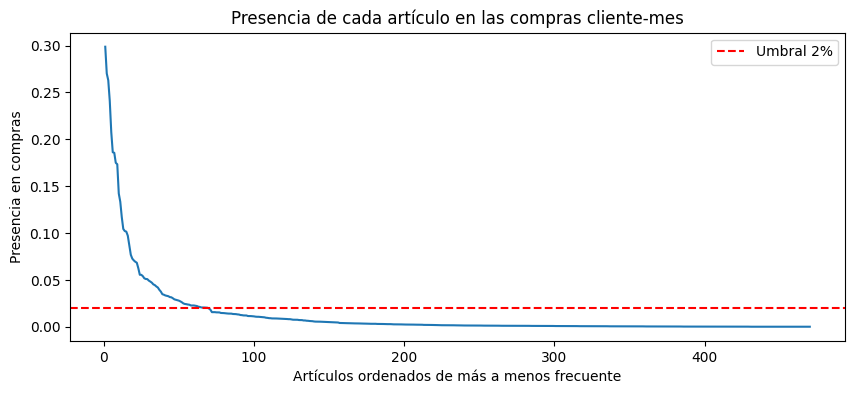

In [7]:
# Total de compras cliente-mes (denominador de la presencia)
n_compras = seco["compra_id"].nunique()

# Por artículo: su descripción y en cuántas compras distintas aparece (como GROUP BY en SQL)
presencia = (seco.groupby("articulo_codigo")
                 .agg(descripcion=("articulo_descripcion", "first"),
                      compras=("compra_id", "nunique"))
                 .sort_values("compras", ascending=False))
# Presencia = proporción de compras en las que aparece el artículo
presencia["presencia"] = presencia["compras"] / n_compras

# Umbral de reducción: artículos presentes en al menos el 2% de las compras
UMBRAL = 0.02
seleccion = presencia[presencia["presencia"] >= UMBRAL]

# Qué proporción de las líneas de factura cubren los artículos seleccionados
cobertura = seco["articulo_codigo"].isin(seleccion.index).mean()

print(f"Artículos con presencia ≥ {UMBRAL:.0%}: {len(seleccion)} de {len(presencia)}")
print(f"Esos artículos cubren el {cobertura:.0%} de las líneas de construcción en seco")

# Curva de presencia: pocos artículos muy frecuentes y una cola larga de artículos raros
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(presencia) + 1), presencia["presencia"].values)
plt.axhline(UMBRAL, color="red", linestyle="--", label=f"Umbral {UMBRAL:.0%}")
plt.xlabel("Artículos ordenados de más a menos frecuente")
plt.ylabel("Presencia en compras")
plt.title("Presencia de cada artículo en las compras cliente-mes")
plt.legend()
plt.show()

## 1.7 · Producto base y rol de cada artículo

Un mismo producto puede venderse con distintos códigos según la presentación o la marca (por ejemplo, tornillos T2 por 100 unidades o en caja de 10.000). Para el modelo son la misma mercadería, así que los agrupamos en un **producto base**. Además, a cada uno le asignamos un **rol**:

- **Principal** (placas y perfiles): es lo que el cliente viene a buscar; se usa como entrada del modelo.
- **Accesorio** (tornillos, cintas, masilla, etc.): es lo que el modelo intenta predecir.
- **Herramienta**: se usa solo como entrada.

La clasificación está en `datos/productos.xlsx`, revisada con conocimiento del rubro.

In [8]:
# Clasificación armada con conocimiento del rubro: código → producto base y rol
productos = pd.read_excel("datos/productos.xlsx", engine="calamine")

# Controles: cada código aparece una sola vez y todos los artículos seleccionados están clasificados
assert productos["articulo_codigo"].is_unique, "Hay códigos repetidos en productos.xlsx"

faltan = set(seleccion.index) - set(productos["articulo_codigo"])
assert not faltan, f"Artículos seleccionados sin producto base: {faltan}"

# Agrega a cada línea su producto base y su rol
seco = seco.merge(productos[["articulo_codigo", "producto_base", "rol"]],
                  on="articulo_codigo", how="left")

# Nos quedamos solo con las líneas de los artículos seleccionados en el paso 1.6
datos_modelo = seco[seco["articulo_codigo"].isin(seleccion.index)].copy()

print("Líneas para el modelo:", len(datos_modelo))
# Cantidad de productos base por rol (principal, accesorio, herramienta)
print("Productos base por rol:")
print(datos_modelo.groupby("rol")["producto_base"].nunique())

Líneas para el modelo: 97010
Productos base por rol:
rol
accesorio      20
herramienta     3
principal      26
Name: producto_base, dtype: int64


## 1.8 · Transformación: tabla de compras

Los algoritmos de aprendizaje automático trabajan con datos tabulares: cada fila es una instancia y cada columna un atributo (clase C2-1). Transformamos las líneas de factura en una tabla donde **cada fila es una compra cliente-mes** y **cada columna un producto base**, con valor **1 si el cliente lo llevó en ese mes y 0 si no**.



In [9]:
# crosstab cuenta cuántas veces aparece cada producto en cada compra (como un PIVOT en SQL);
# clip(upper=1) lo convierte en 1/0: lo llevó o no lo llevó
tabla = pd.crosstab(datos_modelo["compra_id"], datos_modelo["producto_base"]).clip(upper=1)

# Cliente y mes de cada compra, para usarlos en la separación temporal y en la segmentación
info_compras = datos_modelo.groupby("compra_id")[["cliente_id", "mes"]].first()

print("Filas (compras):", tabla.shape[0], "| Columnas (productos base):", tabla.shape[1])
tabla.head()

Filas (compras): 12451 | Columnas (productos base): 49


producto_base,Alambre galvanizado,Arandela EIFS,Base coat,Buña perimetral Z,Cantonera PVC,Cantonera metálica,Cinta de papel,Cinta tramada,Espátula,Fijación del 8,...,T2 mecha,T3 aguja,Tapa de inspección,Tijera corte perfil,Tornillo aletado 8x32,"Travesaño 0,61","Travesaño 1,22",Trincheta,Yeso,Ángulo de ajuste
compra_id,,,,,,,,,,,,,,,,,,,,,
1001_2024-10,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
1001_2024-11,1,0,0,0,0,1,1,0,0,1,...,0,0,0,0,0,1,1,0,0,0
1001_2024-12,1,0,0,0,1,1,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1001_2025-01,0,0,0,1,1,1,1,0,0,1,...,0,0,0,1,0,1,1,0,0,1
1001_2025-02,0,0,1,0,1,1,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0


## 1.9 · Separación en entrenamiento y prueba

En la notebook N02 del curso los datos se separan **al azar** (`train_test_split`). Acá usamos una **separación temporal**: se entrena con los meses anteriores y se prueba con el **último trimestre** (julio a septiembre de 2026). Así se simula el uso real del modelo, que aprende del pasado y predice compras futuras.

Se usan **tres meses** de prueba en lugar de uno porque, en una primera prueba con un solo mes, la evaluación de los accesorios menos frecuentes resultó inestable: con pocos casos positivos, acertar o errar dos compras cambiaba mucho el F1.

Meses de prueba: ['2026-07', '2026-08', '2026-09']
Entrenamiento: 10631 compras (85%)
Prueba:        1820 compras (15%)


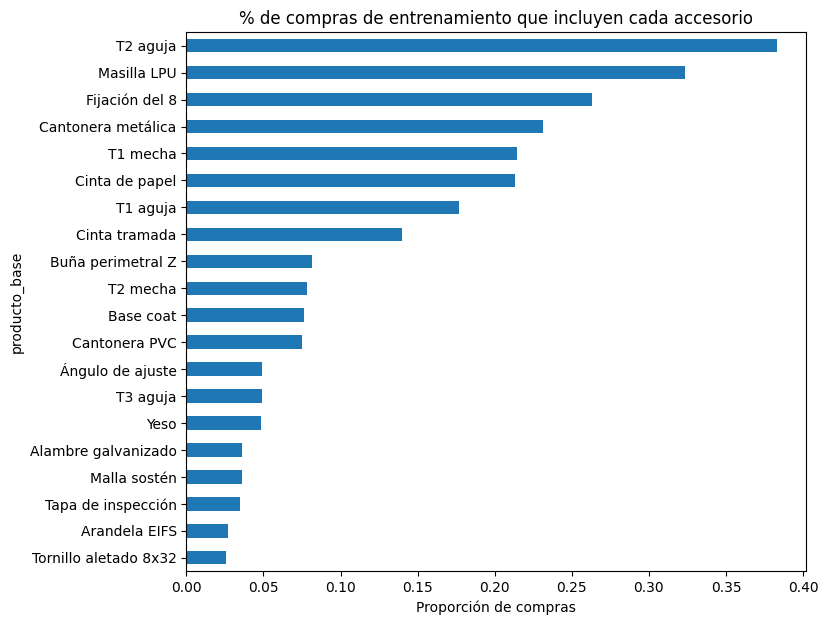

In [10]:
# Separación temporal: los últimos 3 meses (jul-sep 2026) son el período de prueba
N_MESES_PRUEBA = 3

# Lista ordenada de meses y los 3 últimos
meses = sorted(info_compras["mes"].unique())
MESES_PRUEBA = meses[-N_MESES_PRUEBA:]

# True para las compras del período de prueba
es_prueba = info_compras.loc[tabla.index, "mes"].isin(MESES_PRUEBA)

# ~ invierte (NOT): entrenamiento = todo lo que no es prueba
train = tabla[~es_prueba]
test  = tabla[es_prueba]

print("Meses de prueba:", [str(m) for m in MESES_PRUEBA])
print(f"Entrenamiento: {len(train)} compras ({len(train)/len(tabla):.0%})")
print(f"Prueba:        {len(test)} compras ({len(test)/len(tabla):.0%})")

# Productos base con rol "accesorio": son las clases a predecir
accesorios = sorted(productos.loc[productos["rol"] == "accesorio", "producto_base"].unique())

# Frecuencia de cada accesorio en entrenamiento: muestra el desbalance de clases
presencia_acc = train[accesorios].mean().sort_values()
presencia_acc.plot(kind="barh", figsize=(8, 7),
                   title="% de compras de entrenamiento que incluyen cada accesorio")
plt.xlabel("Proporción de compras")
plt.show()

---
# Etapa 2 · Entrenamiento del modelo

Planteamos un problema de **clasificación binaria** (clase C2-2): para cada accesorio, a partir de lo que el cliente compró (**atributos X**), predecir si también lo llevó (**clase y**: 1 = sí, 0 = no).

Empezamos con un solo accesorio, **Masilla LPU**, para recorrer el proceso completo, y luego lo generalizamos a los 20 accesorios.

## 2.1 · Atributos (X) y clase (y)

In [11]:
# Accesorio de ejemplo para recorrer el proceso completo
OBJETIVO = "Masilla LPU"

# X = el resto de los productos de la compra (atributos) · y = si llevó el accesorio (clase)
X_train = train.drop(columns=OBJETIVO)
y_train = train[OBJETIVO]
X_test  = test.drop(columns=OBJETIVO)
y_test  = test[OBJETIVO]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print()
# Proporción de compras que llevan el accesorio en cada período
print(f"Compras con {OBJETIVO} en entrenamiento: {y_train.mean():.1%}")
print(f"Compras con {OBJETIVO} en prueba:        {y_test.mean():.1%}")

# Línea base: accuracy de un modelo que siempre responde "no lleva"
acc_siempre_no = (y_test == 0).mean()
print()
print(f"Línea base: si siempre dijéramos 'no lleva', el accuracy sería {acc_siempre_no:.1%}")

X_train: (10631, 48) | y_train: (10631,)
X_test:  (1820, 48) | y_test:  (1820,)

Compras con Masilla LPU en entrenamiento: 32.4%
Compras con Masilla LPU en prueba:        33.0%

Línea base: si siempre dijéramos 'no lleva', el accuracy sería 67.0%


## 2.2 · Primer modelo: árbol de decisión

Entrenamos un **árbol de decisión** (clase C2-2, notebook N02) con el criterio de **entropía**: en cada nodo, el árbol elige el producto que más reduce el "desorden" de la clase, es decir, el que mejor separa las compras que llevan masilla de las que no (ganancia de información).

Limitamos la profundidad del árbol a 4 niveles: como vimos en la clase C3-2, los árboles muy complejos tienden a **sobreajustar** (memorizar el entrenamiento) y además se vuelven imposibles de interpretar.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# Árbol con entropía (ganancia de información), como en N02.
# max_depth=4 limita la profundidad para evitar el sobreajuste y que siga siendo legible;
# random_state=42 hace que el resultado sea reproducible
arbol = DecisionTreeClassifier(criterion="entropy", max_depth=4,
                               min_samples_split=10, random_state=42)
# Entrenamiento con los meses anteriores
arbol.fit(X_train, y_train)

# Predicción sobre las compras de prueba (el modelo no las vio)
y_pred = arbol.predict(X_test)

# Accuracy contra la línea base, y F1 (más adecuado porque las clases están desbalanceadas)
print(f"Accuracy en prueba: {accuracy_score(y_test, y_pred):.1%}   (línea base: {acc_siempre_no:.1%})")
print(f"F1 en prueba:       {f1_score(y_test, y_pred):.2f}")

Accuracy en prueba: 79.7%   (línea base: 67.0%)
F1 en prueba:       0.67


## 2.3 · ¿En qué se equivoca? Matriz de confusión

La **matriz de confusión** cruza lo que predijo el modelo con lo que realmente ocurrió en las compras de prueba. Permite ver los dos tipos de error por separado:
- **Falsos positivos:** el modelo dijo "lleva masilla" y no la llevó.
- **Falsos negativos:** el modelo dijo "no lleva" y sí la llevó.

Las métricas **precisión** y **recall** resumen esos errores, y el **F1** las combina en un solo número.

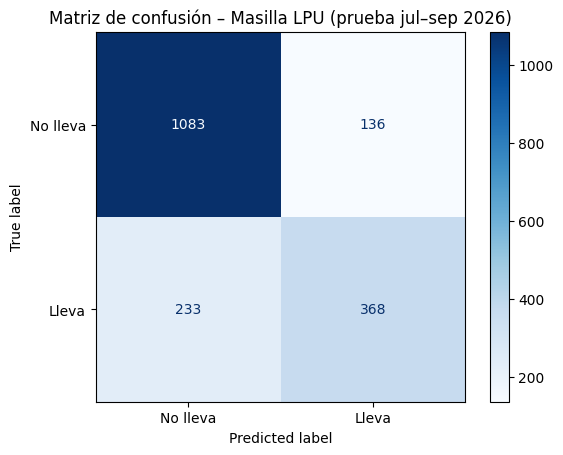

              precision    recall  f1-score   support

    No lleva       0.82      0.89      0.85      1219
       Lleva       0.73      0.61      0.67       601

    accuracy                           0.80      1820
   macro avg       0.78      0.75      0.76      1820
weighted avg       0.79      0.80      0.79      1820



In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Matriz de confusión: filas = lo que pasó, columnas = lo que predijo el modelo
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No lleva", "Lleva"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión – {OBJETIVO} (prueba jul–sep 2026)")
plt.show()

# Precisión, recall y F1 de cada clase
print(classification_report(y_test, y_pred, target_names=["No lleva", "Lleva"]))

## 2.4 · ¿Qué aprendió el árbol?

Una ventaja del árbol de decisión es su **interpretabilidad**: se puede dibujar y leer como un conjunto de reglas "si… entonces…". Esto se relaciona con la dimensión de **transparencia y explicabilidad** de la ética en IA (clase C8): el vendedor puede entender *por qué* el modelo sugiere un accesorio.

También calculamos la **importancia de cada atributo**: cuánto contribuye cada producto, en total, a reducir la entropía en los cortes del árbol.

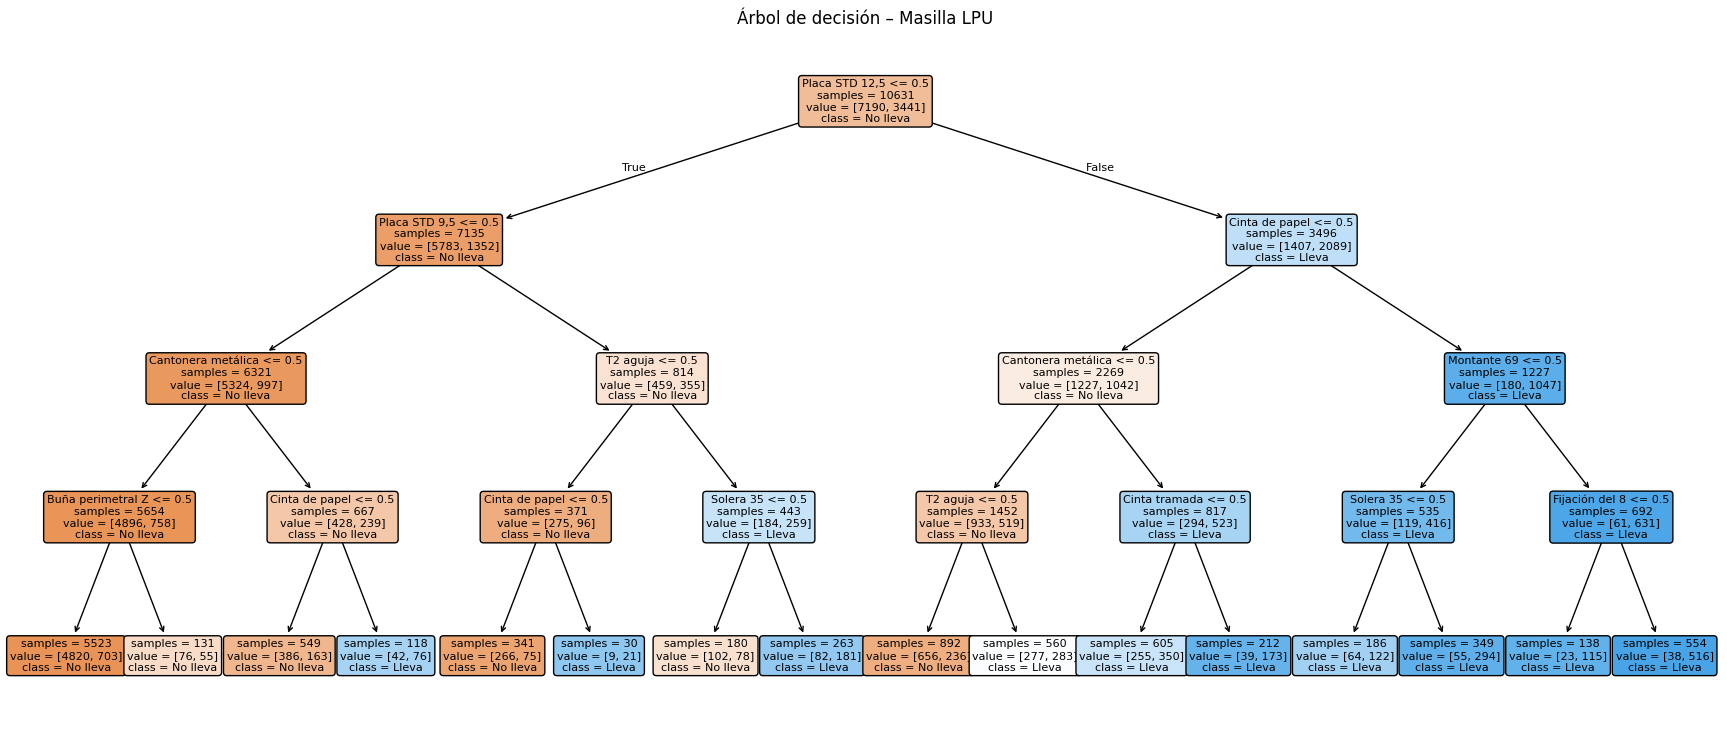

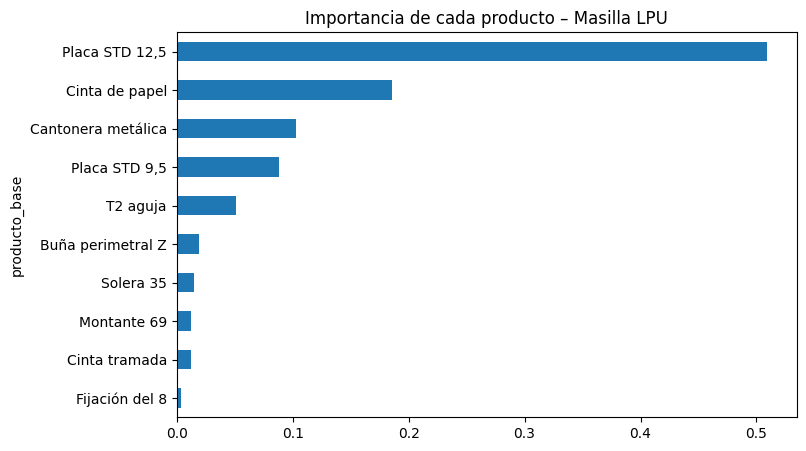

In [14]:
from sklearn.tree import plot_tree

# Dibujo del árbol: cada nodo es una regla "si lleva / no lleva este producto"
plt.figure(figsize=(22, 9))
plot_tree(arbol, feature_names=X_train.columns, class_names=["No lleva", "Lleva"],
          filled=True, rounded=True, impurity=False, fontsize=8)
plt.title(f"Árbol de decisión – {OBJETIVO}")
plt.show()

# Importancia de cada producto: cuánto reduce la entropía en total en los cortes del árbol
importancia = pd.Series(arbol.feature_importances_, index=X_train.columns)
importancia[importancia > 0].sort_values().plot(kind="barh", figsize=(8, 5),
                                                title=f"Importancia de cada producto – {OBJETIVO}")
plt.show()

## 2.5 · Comparación de algoritmos

Entrenamos los cuatro algoritmos de la propuesta con los mismos datos y los evaluamos sobre el mismo período de prueba (julio a septiembre 2026):

| Algoritmo | Idea | Clase |
|---|---|---|
| Regresión logística | Combina linealmente los atributos y transforma el resultado en una probabilidad (función sigmoide) | Programa U2 / C5 (sigmoide) |
| Árbol de decisión | Reglas "si… entonces…" elegidas por ganancia de información | C2-2 |
| k-NN | Busca las *k* compras más parecidas y vota la clase mayoritaria | C2-2 |
| Random Forest | Muchos árboles entrenados con muestras distintas (bagging) que votan | C3-2 |

Se incluye también la **línea base** ("siempre no lleva") como referencia.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

# Los cuatro algoritmos de la propuesta, con los mismos datos de entrenamiento y prueba
modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión":   DecisionTreeClassifier(criterion="entropy", max_depth=4,
                                                  min_samples_split=10, random_state=42),
    "k-NN (k=5)":          KNeighborsClassifier(n_neighbors=5),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

# Entrena cada modelo, predice la prueba y guarda sus métricas
resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        # zero_division=0: si el modelo nunca predice "lleva", la precisión vale 0 en lugar de dar error
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

# La línea base se agrega como referencia: el F1 de "siempre no" es 0
resultados.append({"Modelo": "Línea base (siempre 'no')", "Accuracy": acc_siempre_no,
                   "Precisión": 0, "Recall": 0, "F1": 0})

# Tabla de resultados ordenada por F1
comparacion = pd.DataFrame(resultados).set_index("Modelo").round(3)
comparacion.sort_values("F1", ascending=False)

,Accuracy,Precisión,Recall,F1
Modelo,,,,
Random Forest,0.830,0.776,0.681,0.725
k-NN (k=5),0.830,0.799,0.647,0.715
Árbol de decisión,0.797,0.730,0.612,0.666
Regresión logística,0.798,0.764,0.564,0.649
Línea base (siempre 'no'),0.670,0.000,0.000,0.000


## 2.6 · Generalización: los 20 accesorios

Repetimos el procedimiento para cada accesorio: en cada caso, ese accesorio es la clase *y* y el resto de los productos son los atributos *X*. Entrenamos los cuatro algoritmos con octubre 2024 a junio 2026 y los evaluamos con julio a septiembre 2026. El resultado es una tabla de **F1 por accesorio y por algoritmo**, que muestra qué accesorios se pueden predecir bien y cuál algoritmo funciona mejor en general.

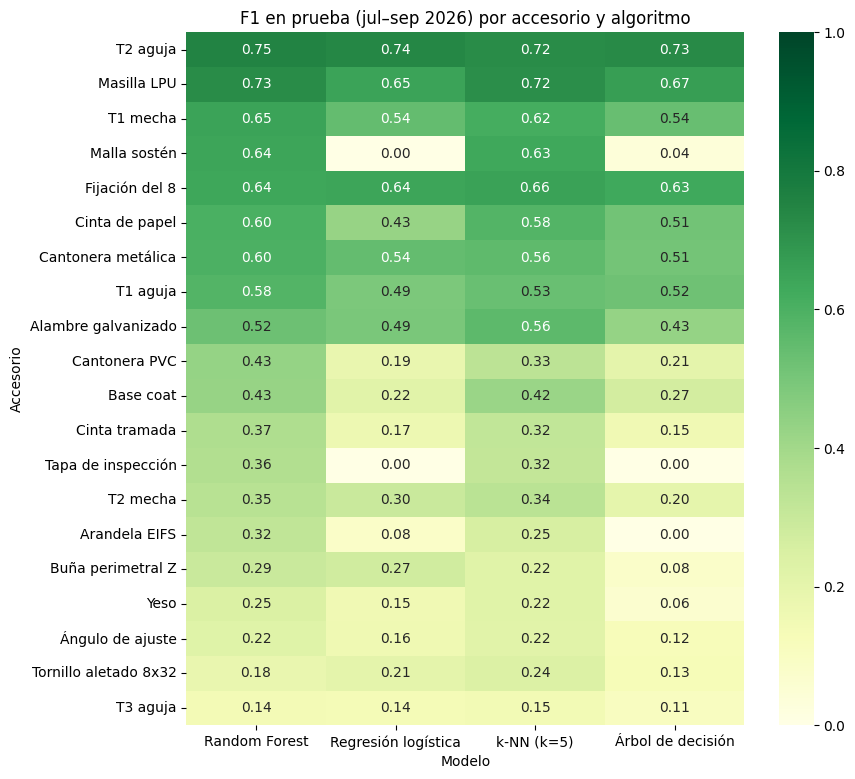

F1 promedio por algoritmo:
Modelo
Random Forest          0.453
k-NN (k=5)             0.430
Regresión logística    0.320
Árbol de decisión      0.295
Name: F1, dtype: float64


In [16]:
# Para cada accesorio: ese accesorio es la clase y y el resto de los productos son los atributos X
filas = []
for acc in accesorios:
    Xtr, ytr = train.drop(columns=acc), train[acc]
    Xte, yte = test.drop(columns=acc),  test[acc]

    # Se entrenan los cuatro algoritmos y se guarda el F1 de cada uno.
    # También se guarda cuántos casos positivos hay, para ver el efecto de la escasez de ejemplos
    for nombre, modelo in modelos.items():
        modelo.fit(Xtr, ytr)
        pred = modelo.predict(Xte)
        filas.append({
            "Accesorio": acc,
            "Modelo": nombre,
            "F1": f1_score(yte, pred, zero_division=0),
            "Accuracy": accuracy_score(yte, pred),
            "Positivos train": int(ytr.sum()),
            "Positivos test": int(yte.sum()),
        })

# Tabla de F1: una fila por accesorio y una columna por algoritmo (como un PIVOT en SQL)
res = pd.DataFrame(filas)

f1_tabla = res.pivot(index="Accesorio", columns="Modelo", values="F1")
f1_tabla = f1_tabla.sort_values("Random Forest", ascending=False)

# Mapa de calor del F1: verde oscuro = el modelo predice bien ese accesorio
plt.figure(figsize=(9, 9))
sns.heatmap(f1_tabla, annot=True, fmt=".2f", cmap="YlGn", vmin=0, vmax=1)
plt.title("F1 en prueba (jul–sep 2026) por accesorio y algoritmo")
plt.show()

# Promedio de F1 de cada algoritmo sobre los 20 accesorios
print("F1 promedio por algoritmo:")
print(res.groupby("Modelo")["F1"].mean().sort_values(ascending=False).round(3))

## 2.7 · Decisión: modelo y accesorios confiables

- **Modelo elegido: Random Forest**, que obtiene el mayor F1 promedio y gana en la mayoría de los accesorios. Coincide con lo visto en la clase C3-2: combinar muchos árboles (bagging) reduce la varianza de un árbol individual.
- **Accesorios confiables:** se consideran para la detección de ventas perdidas solo los accesorios con **F1 ≥ 0,5**. Si un modelo predice mal un accesorio, sus "ventas perdidas" serían mayormente ruido.
- Los accesorios menos frecuentes se predicen peor por la escasez de ejemplos. Pasar de 3 a 24 meses de datos los mejoró (por ejemplo, la malla sostén subió de 0,47 a 0,64 de F1), pero algunos siguen por debajo del umbral.

In [17]:
# Algoritmo elegido y F1 mínimo para considerar confiable un accesorio
MODELO_ELEGIDO = "Random Forest"
F1_MINIMO = 0.5

# Lista de accesorios que el Random Forest predice con F1 ≥ 0,5
confiables = f1_tabla.index[f1_tabla[MODELO_ELEGIDO] >= F1_MINIMO].tolist()

print(f"Accesorios con F1 ≥ {F1_MINIMO} usando {MODELO_ELEGIDO}: {len(confiables)} de {len(accesorios)}")
for acc in confiables:
    print(f"  - {acc:<20} F1 = {f1_tabla.loc[acc, MODELO_ELEGIDO]:.2f}")

Accesorios con F1 ≥ 0.5 usando Random Forest: 9 de 20
  - T2 aguja             F1 = 0.75
  - Masilla LPU          F1 = 0.73
  - T1 mecha             F1 = 0.65
  - Malla sostén         F1 = 0.64
  - Fijación del 8       F1 = 0.64
  - Cinta de papel       F1 = 0.60
  - Cantonera metálica   F1 = 0.60
  - T1 aguja             F1 = 0.58
  - Alambre galvanizado  F1 = 0.52


## 2.8 · Ajuste de hiperparámetros (Grid Search con validación)

Para elegir los hiperparámetros del Random Forest sin usar el período de prueba, dividimos el entrenamiento en dos: los meses de **octubre 2024 a marzo 2026** para entrenar y el trimestre **abril a junio 2026** como conjunto de **validación**. Probamos todas las combinaciones de una grilla de valores (*Grid Search*, clase C2-1) y elegimos la que obtiene el mayor **F1 promedio en validación** sobre los 20 accesorios. El trimestre de prueba (julio a septiembre 2026) queda reservado para la evaluación final.

Hiperparámetros explorados:
- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: cantidad mínima de compras en cada hoja (controla el sobreajuste).
- `class_weight`: con `"balanced"`, el modelo da más peso a la clase minoritaria ("lleva"), lo que puede mejorar el recall.

In [18]:
from sklearn.model_selection import ParameterGrid

# Validación: los últimos 3 meses del entrenamiento (abr-jun 2026).
# Así se eligen los hiperparámetros sin tocar el período de prueba
meses_train = info_compras.loc[train.index, "mes"]
meses_ent = sorted(meses_train.unique())
MESES_VALID = meses_ent[-N_MESES_PRUEBA:]

es_valid = meses_train.isin(MESES_VALID)
sub_train = train[~es_valid]
valid     = train[es_valid]
print(f"Sub-entrenamiento: {len(sub_train)} compras | "
      f"Validación {[str(m) for m in MESES_VALID]}: {len(valid)} compras")

# Grilla de hiperparámetros a probar: 3 × 3 × 2 = 18 combinaciones
grilla = ParameterGrid({
    "max_depth":        [None, 6, 10],
    "min_samples_leaf": [1, 3, 5],
    "class_weight":     [None, "balanced"],
})

# Para cada combinación: se entrena un Random Forest por accesorio con el sub-entrenamiento,
# se mide el F1 en validación y se promedia sobre los 20 accesorios
resultados_grilla = []
for i, params in enumerate(grilla, start=1):
    f1s = []
    for acc in accesorios:
        # **params pasa los valores de la combinación como parámetros del modelo
        rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **params)
        rf.fit(sub_train.drop(columns=acc), sub_train[acc])
        pred = rf.predict(valid.drop(columns=acc))
        f1s.append(f1_score(valid[acc], pred, zero_division=0))
    resultados_grilla.append({**params, "F1 validación": np.mean(f1s)})
    # Contador de progreso (la celda tarda varios minutos)
    print(f"Configuración {i}/{len(grilla)} terminada")

# Combinaciones ordenadas de mejor a peor F1 promedio en validación
grilla_df = pd.DataFrame(resultados_grilla).sort_values("F1 validación", ascending=False)
grilla_df.head(10)

Sub-entrenamiento: 8949 compras | Validación ['2026-04', '2026-05', '2026-06']: 1682 compras
Configuración 1/18 terminada
Configuración 2/18 terminada
Configuración 3/18 terminada
Configuración 4/18 terminada
Configuración 5/18 terminada
Configuración 6/18 terminada
Configuración 7/18 terminada
Configuración 8/18 terminada
Configuración 9/18 terminada
Configuración 10/18 terminada
Configuración 11/18 terminada
Configuración 12/18 terminada
Configuración 13/18 terminada
Configuración 14/18 terminada
Configuración 15/18 terminada
Configuración 16/18 terminada
Configuración 17/18 terminada
Configuración 18/18 terminada


,class_weight,max_depth,min_samples_leaf,F1 validación
10,balanced,NaN,3,0.500631
11,balanced,NaN,5,0.487083
0,None,NaN,1,0.449974
16,balanced,10.0,3,0.443189
17,balanced,10.0,5,0.440446
9,balanced,NaN,1,0.435771
13,balanced,6.0,3,0.426953
12,balanced,6.0,1,0.426917
1,None,NaN,3,0.424443
15,balanced,10.0,1,0.424113


## 2.9 · Modelo final y evaluación en prueba

Con los hiperparámetros elegidos en validación, entrenamos el Random Forest final con **todo el período de entrenamiento** (octubre 2024 a junio 2026) y lo evaluamos **por única vez** en el período de prueba (julio a septiembre 2026). Comparamos contra el Random Forest con los valores por defecto del paso 2.6.

In [19]:
# Mejor combinación de la grilla. pandas guarda None como NaN, por eso se convierte de nuevo
# a None (y los números a int) antes de pasarla a scikit-learn
mejor = grilla_df.iloc[0]
MEJORES_PARAMS = {
    "max_depth":        None if pd.isna(mejor["max_depth"]) else int(mejor["max_depth"]),
    "min_samples_leaf": int(mejor["min_samples_leaf"]),
    "class_weight":     None if pd.isna(mejor["class_weight"]) else mejor["class_weight"],
}
print("Hiperparámetros elegidos:", MEJORES_PARAMS)

# Random Forest final por accesorio: se entrena con todo el entrenamiento y se evalúa en prueba
f1_final = {}
modelos_finales = {}
for acc in accesorios:
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, **MEJORES_PARAMS)
    rf.fit(train.drop(columns=acc), train[acc])
    pred = rf.predict(test.drop(columns=acc))
    f1_final[acc] = f1_score(test[acc], pred, zero_division=0)
    modelos_finales[acc] = rf

# Comparación del F1 en prueba: valores por defecto contra ajuste global
comparacion_rf = pd.DataFrame({
    "RF por defecto": f1_tabla["Random Forest"],
    "RF ajustado":    pd.Series(f1_final),
})
comparacion_rf["Diferencia"] = comparacion_rf["RF ajustado"] - comparacion_rf["RF por defecto"]
comparacion_rf = comparacion_rf.sort_values("RF ajustado", ascending=False).round(2)

print()
print("F1 promedio por defecto:", round(comparacion_rf["RF por defecto"].mean(), 3))
print("F1 promedio ajustado:   ", round(comparacion_rf["RF ajustado"].mean(), 3))
comparacion_rf

Hiperparámetros elegidos: {'max_depth': None, 'min_samples_leaf': 3, 'class_weight': 'balanced'}

F1 promedio por defecto: 0.452
F1 promedio ajustado:    0.488


,RF por defecto,RF ajustado,Diferencia
T2 aguja,0.75,0.77,0.02
Masilla LPU,0.73,0.75,0.02
T1 mecha,0.65,0.69,0.03
Fijación del 8,0.64,0.68,0.04
T1 aguja,0.58,0.67,0.08
Cinta de papel,0.60,0.64,0.04
Cantonera metálica,0.60,0.64,0.04
Cinta tramada,0.37,0.53,0.16
Base coat,0.43,0.53,0.10
Alambre galvanizado,0.52,0.48,-0.04


## 2.10 · Ajuste por accesorio

El ajuste global mejoró el F1 promedio, pero perjudicó de forma consistente a algunos accesorios (malla sostén, tapa de inspección, arandela EIFS), que ya habían empeorado en la prueba con menos datos. Esto indica que **la mejor configuración depende del accesorio**.

Por eso elegimos, **para cada accesorio por separado**, la configuración con mayor F1 **en validación** (abril a junio 2026). La decisión se sigue tomando sin mirar el período de prueba, que se usa una única vez para la evaluación final.

In [20]:
# Igual que el Grid Search del paso 2.8, pero guardando el F1 en validación de cada accesorio por separado
resultados_acc = []
for i, params in enumerate(grilla, start=1):
    for acc in accesorios:
        rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **params)
        rf.fit(sub_train.drop(columns=acc), sub_train[acc])
        pred = rf.predict(valid.drop(columns=acc))
        resultados_acc.append({"Accesorio": acc, **params,
                               "F1 validación": f1_score(valid[acc], pred, zero_division=0)})
    print(f"Configuración {i}/{len(grilla)} terminada")

# Tabla con una fila por combinación y accesorio
res_acc = pd.DataFrame(resultados_acc)

# Para cada accesorio, la combinación con mayor F1 en validación (idxmax = fila del máximo)
mejor_por_acc = res_acc.loc[res_acc.groupby("Accesorio")["F1 validación"].idxmax()].set_index("Accesorio")

# Modelos finales: cada accesorio con su propia configuración, entrenado con todo el
# entrenamiento y evaluado una única vez en prueba
f1_por_acc = {}
modelos_finales = {}
for acc, fila in mejor_por_acc.iterrows():
    # Conversión de NaN a None y a int, igual que en el paso 2.9
    params = {
        "max_depth":        None if pd.isna(fila["max_depth"]) else int(fila["max_depth"]),
        "min_samples_leaf": int(fila["min_samples_leaf"]),
        "class_weight":     None if pd.isna(fila["class_weight"]) else fila["class_weight"],
    }
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, **params)
    rf.fit(train.drop(columns=acc), train[acc])
    pred = rf.predict(test.drop(columns=acc))
    f1_por_acc[acc] = f1_score(test[acc], pred, zero_division=0)
    # Se guarda el modelo de cada accesorio para la Etapa 3
    modelos_finales[acc] = rf

# Se agrega la nueva columna a la comparación del paso 2.9
comparacion_rf["Ajuste por accesorio"] = pd.Series(f1_por_acc).round(2)
comparacion_rf = comparacion_rf.drop(columns="Diferencia").sort_values("Ajuste por accesorio", ascending=False)

# F1 promedio de las tres variantes
print()
print("F1 promedio por defecto:        ", round(comparacion_rf["RF por defecto"].mean(), 3))
print("F1 promedio ajuste global:      ", round(comparacion_rf["RF ajustado"].mean(), 3))
print("F1 promedio ajuste por accesorio:", round(comparacion_rf["Ajuste por accesorio"].mean(), 3))
# Tabla final con la configuración elegida para cada accesorio
comparacion_rf.join(mejor_por_acc[["class_weight", "max_depth", "min_samples_leaf"]])

Configuración 1/18 terminada
Configuración 2/18 terminada
Configuración 3/18 terminada
Configuración 4/18 terminada
Configuración 5/18 terminada
Configuración 6/18 terminada
Configuración 7/18 terminada
Configuración 8/18 terminada
Configuración 9/18 terminada
Configuración 10/18 terminada
Configuración 11/18 terminada
Configuración 12/18 terminada
Configuración 13/18 terminada
Configuración 14/18 terminada
Configuración 15/18 terminada
Configuración 16/18 terminada
Configuración 17/18 terminada
Configuración 18/18 terminada

F1 promedio por defecto:         0.452
F1 promedio ajuste global:       0.488
F1 promedio ajuste por accesorio: 0.511


,RF por defecto,RF ajustado,Ajuste por accesorio,class_weight,max_depth,min_samples_leaf
T2 aguja,0.75,0.77,0.77,balanced,NaN,5
Masilla LPU,0.73,0.75,0.75,balanced,NaN,3
T1 mecha,0.65,0.69,0.69,balanced,NaN,3
Fijación del 8,0.64,0.68,0.68,balanced,NaN,3
T1 aguja,0.58,0.67,0.67,balanced,NaN,3
Cinta de papel,0.60,0.64,0.64,balanced,NaN,3
Malla sostén,0.64,0.37,0.64,None,NaN,3
Cantonera metálica,0.60,0.64,0.63,balanced,NaN,5
Base coat,0.43,0.53,0.53,balanced,NaN,3
Cinta tramada,0.37,0.53,0.53,balanced,NaN,3


## 2.11 · Modelo final y accesorios confiables

El modelo final es un **Random Forest con la configuración elegida para cada accesorio en validación**. Para la detección de ventas perdidas (objetivo 2) se usan solo los accesorios con **F1 ≥ 0,5 en el período de prueba**.

In [21]:
# Accesorios confiables: F1 ≥ 0,5 con el modelo final. Son los que se usan para detectar ventas perdidas
F1_MINIMO = 0.5

confiables = comparacion_rf.index[comparacion_rf["Ajuste por accesorio"] >= F1_MINIMO].tolist()

print(f"Accesorios confiables (F1 ≥ {F1_MINIMO}): {len(confiables)} de {len(accesorios)}")
for acc in confiables:
    print(f"  - {acc:<20} F1 = {comparacion_rf.loc[acc, 'Ajuste por accesorio']:.2f}")

Accesorios confiables (F1 ≥ 0.5): 11 de 20
  - T2 aguja             F1 = 0.77
  - Masilla LPU          F1 = 0.75
  - T1 mecha             F1 = 0.69
  - Fijación del 8       F1 = 0.68
  - T1 aguja             F1 = 0.67
  - Cinta de papel       F1 = 0.64
  - Malla sostén         F1 = 0.64
  - Cantonera metálica   F1 = 0.63
  - Base coat            F1 = 0.53
  - Cinta tramada        F1 = 0.53
  - Alambre galvanizado  F1 = 0.52


---
# Etapa 3 · Evaluación y aplicación: detección de ventas perdidas

Con el modelo final evaluado, lo aplicamos al objetivo de negocio. Para cada compra del período de prueba (julio a septiembre 2026) y cada accesorio confiable, el modelo estima la **probabilidad** de que el cliente lo lleve, a partir del resto de su compra.

Una **posible venta perdida** es una compra en la que esa probabilidad es alta, pero el cliente **no llevó** el accesorio.

## 3.1 · Probabilidad de llevar cada accesorio

Probabilidades calculadas: (1820, 11)


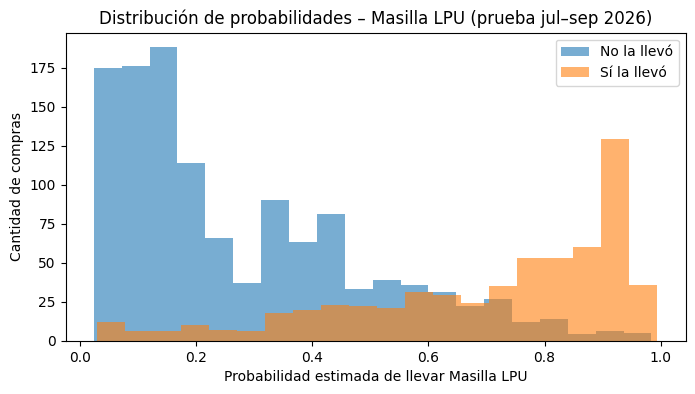

In [22]:
# Probabilidad de llevar cada accesorio confiable en cada compra de prueba.
# predict_proba devuelve [prob. no, prob. sí]; [:, 1] toma la columna del "sí"
probas = pd.DataFrame(
    {acc: modelos_finales[acc].predict_proba(test.drop(columns=acc))[:, 1] for acc in confiables},
    index=test.index,
)

print("Probabilidades calculadas:", probas.shape)

# Histograma de ejemplo: probabilidades de las compras que llevaron masilla y de las que no
acc_ej = "Masilla LPU"
plt.figure(figsize=(8, 4))
plt.hist(probas.loc[test[acc_ej] == 0, acc_ej], bins=20, alpha=0.6, label="No la llevó")
plt.hist(probas.loc[test[acc_ej] == 1, acc_ej], bins=20, alpha=0.6, label="Sí la llevó")
plt.xlabel(f"Probabilidad estimada de llevar {acc_ej}")
plt.ylabel("Cantidad de compras")
plt.title(f"Distribución de probabilidades – {acc_ej} (prueba jul–sep 2026)")
plt.legend()
plt.show()

## 3.2 · Elección del umbral de probabilidad

Para decidir a partir de qué probabilidad consideramos una posible venta perdida, comparamos varios umbrales. Para cada uno medimos cuántas compras superan esa probabilidad, qué porcentaje de ellas **efectivamente** llevó el accesorio (si es alto, el modelo es confiable en esa zona) y cuántas no lo llevaron, que son las **posibles ventas perdidas**.

In [23]:
# Umbrales a comparar
umbrales = [0.5, 0.6, 0.7, 0.8]

# Para cada umbral y accesorio: cuántas compras superan la probabilidad y cuántas de ellas
# NO llevaron el accesorio (posibles ventas perdidas)
filas = []
for u in umbrales:
    for acc in confiables:
        alta = probas[acc] >= u
        llevaron = test.loc[alta, acc]
        filas.append({"Umbral": u, "Accesorio": acc,
                      "Compras con prob. alta": int(alta.sum()),
                      "Ventas perdidas": int((llevaron == 0).sum())})

# Totales por umbral, porcentaje que sí lo llevó (confiabilidad) y ventas perdidas por mes
por_umbral = pd.DataFrame(filas).groupby("Umbral")[["Compras con prob. alta", "Ventas perdidas"]].sum()
por_umbral["% que sí lo llevó"] = (1 - por_umbral["Ventas perdidas"] / por_umbral["Compras con prob. alta"]).round(3)
por_umbral["Ventas perdidas por mes"] = (por_umbral["Ventas perdidas"] / N_MESES_PRUEBA).round(0)
por_umbral

,Compras con prob. alta,Ventas perdidas,% que sí lo llevó,Ventas perdidas por mes
Umbral,,,,
0.5,4988,2001,0.599,667.0
0.6,3839,1244,0.676,415.0
0.7,2769,679,0.755,226.0
0.8,1753,284,0.838,95.0


## 3.3 · Lista de posibles ventas perdidas

Se considera **posible venta perdida** cada combinación de compra y accesorio confiable en la que el modelo estimó una probabilidad de al menos **0,7** y el cliente **no** llevó el accesorio. Se clasifican en dos niveles:

- **Prioridad alta** (probabilidad ≥ 0,8): en el período de prueba, el 84% de las compras con esa probabilidad sí llevaron el accesorio.
- **Prioridad media** (entre 0,7 y 0,8): el 61% lo llevó.

Posibles ventas perdidas en el período de prueba: 679
Compras distintas afectadas: 522 de 1820



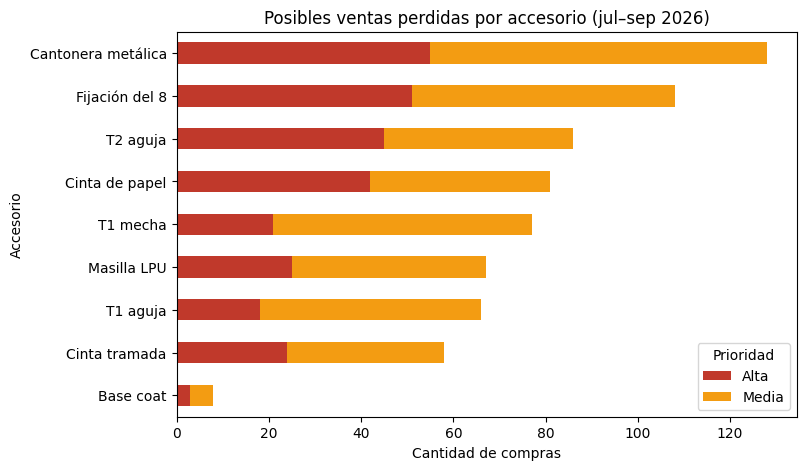

Prioridad,Alta,Media,Total
Accesorio,,,
Cantonera metálica,55,73,128
Fijación del 8,51,57,108
T2 aguja,45,41,86
Cinta de papel,42,39,81
T1 mecha,21,56,77
Masilla LPU,25,42,67
T1 aguja,18,48,66
Cinta tramada,24,34,58
Base coat,3,5,8


In [24]:
# Dos niveles de prioridad, elegidos en el paso 3.2
UMBRAL_MEDIA = 0.7
UMBRAL_ALTA  = 0.8

# Pasa la tabla a formato largo: una fila por compra y accesorio, con su probabilidad
# y si lo llevó (stack es lo contrario de un PIVOT)
largo = probas.rename_axis(columns="Accesorio").stack().rename("Probabilidad").to_frame()
largo["Lo llevó"] = test[confiables].rename_axis(columns="Accesorio").stack()

# Posible venta perdida: probabilidad ≥ 0,7 y no lo llevó
ventas_perdidas = largo[(largo["Probabilidad"] >= UMBRAL_MEDIA) & (largo["Lo llevó"] == 0)].reset_index()
# np.where funciona como CASE WHEN en SQL: Alta si la probabilidad es ≥ 0,8, si no Media
ventas_perdidas["Prioridad"] = np.where(ventas_perdidas["Probabilidad"] >= UMBRAL_ALTA, "Alta", "Media")
# Agrega el cliente y el mes de cada compra
ventas_perdidas = ventas_perdidas.merge(info_compras, left_on="compra_id", right_index=True)

print("Posibles ventas perdidas en el período de prueba:", len(ventas_perdidas))
print("Compras distintas afectadas:", ventas_perdidas["compra_id"].nunique(), "de", len(test))
print()

# Cantidad de ventas perdidas por accesorio y prioridad
resumen_acc = pd.crosstab(ventas_perdidas["Accesorio"], ventas_perdidas["Prioridad"])
resumen_acc["Total"] = resumen_acc.sum(axis=1)
resumen_acc = resumen_acc.sort_values("Total", ascending=False)

# Gráfico de barras apiladas: rojo = prioridad alta, naranja = media
resumen_acc[["Alta", "Media"]].plot(kind="barh", stacked=True, figsize=(8, 5),
                                    color=["#c0392b", "#f39c12"],
                                    title="Posibles ventas perdidas por accesorio (jul–sep 2026)")
plt.xlabel("Cantidad de compras")
plt.gca().invert_yaxis()
plt.show()

resumen_acc

## 3.4 · Ejemplos concretos

Para ilustrar el resultado, mostramos tres compras reales del período de prueba con las ventas perdidas más claras (mayor probabilidad): qué llevó el cliente y qué accesorios le faltaron según el modelo.

In [25]:
# Función que muestra, para una compra, qué llevó el cliente y qué accesorios le faltaron
def mostrar_compra(compra_id):
    cliente = info_compras.loc[compra_id, "cliente_id"]
    mes     = info_compras.loc[compra_id, "mes"]
    # Productos con valor 1 en la tabla de compras
    llevo   = test.columns[test.loc[compra_id] == 1].tolist()
    # Ventas perdidas de esa compra, de mayor a menor probabilidad
    falta   = (ventas_perdidas[ventas_perdidas["compra_id"] == compra_id]
               .sort_values("Probabilidad", ascending=False))

    print(f"Cliente {cliente} – {mes}")
    print(f"  Llevó ({len(llevo)}): {', '.join(llevo)}")
    for _, fila in falta.iterrows():
        print(f"  ✗ Le faltó: {fila['Accesorio']:<20} probabilidad {fila['Probabilidad']:.0%}  (prioridad {fila['Prioridad']})")
    print()


# Las 3 compras con la venta perdida más probable (una sola vez por compra)
ejemplos = (ventas_perdidas[ventas_perdidas["Prioridad"] == "Alta"]
            .sort_values("Probabilidad", ascending=False)
            .drop_duplicates("compra_id")
            .head(3)["compra_id"])

for compra in ejemplos:
    mostrar_compra(compra)

Cliente 2546 – 2026-07
  Llevó (12): Cantonera metálica, Cinta de papel, Cinta tramada, Fijación del 8, Montante 34, Montante 69, Placa STD 12,5, Placa verde 12,5, Solera 35, Solera 70, T1 mecha, T2 aguja
  ✗ Le faltó: Masilla LPU          probabilidad 98%  (prioridad Alta)

Cliente 1574 – 2026-07
  Llevó (10): Cantonera metálica, Cinta de papel, Fijación del 8, Masilla LPU, Montante 34, Montante 69, Placa STD 12,5, Solera 35, Solera 70, T1 aguja
  ✗ Le faltó: T2 aguja             probabilidad 97%  (prioridad Alta)

Cliente 2896 – 2026-09
  Llevó (8): Cantonera metálica, Cinta de papel, Fijación del 8, Montante 69, Placa STD 12,5, Solera 70, T1 mecha, T2 aguja
  ✗ Le faltó: Masilla LPU          probabilidad 97%  (prioridad Alta)



## 3.5 · Clientes con más oportunidades

Agrupamos las posibles ventas perdidas por cliente para identificar a quiénes conviene contactar primero. Para cada cliente se informa la cantidad de ventas perdidas (total y de prioridad alta), el accesorio que más le falta y cuántas compras hizo en el período, para distinguir a los clientes que compran mucho de los que realmente dejan accesorios afuera.

In [26]:
# Cantidad de compras de cada cliente en el período de prueba
compras_cliente = info_compras.loc[test.index].groupby("cliente_id").size()

# Por cliente: total de ventas perdidas, cuántas son de prioridad alta y el accesorio que más le falta.
# lambda define una función corta en línea
ranking = ventas_perdidas.groupby("cliente_id").agg(
    ventas_perdidas=("Accesorio", "size"),
    prioridad_alta=("Prioridad", lambda s: (s == "Alta").sum()),
    accesorio_mas_faltante=("Accesorio", lambda s: s.value_counts().index[0]),
)
# Ventas perdidas por compra, para no confundir a un cliente que compra mucho con uno que deja
# accesorios afuera
ranking["compras_en_prueba"] = compras_cliente
ranking["faltantes_por_compra"] = (ranking["ventas_perdidas"] / ranking["compras_en_prueba"]).round(1)
ranking = ranking.sort_values(["prioridad_alta", "ventas_perdidas"], ascending=False)

# Qué tan concentradas están las ventas perdidas en pocos clientes
print("Clientes con al menos una posible venta perdida:", len(ranking),
      "de", compras_cliente.size, "clientes activos en el período")
top10 = ranking.head(10)
print(f"Los 10 primeros concentran {top10['ventas_perdidas'].sum()} de {len(ventas_perdidas)} "
      f"ventas perdidas ({top10['ventas_perdidas'].sum() / len(ventas_perdidas):.0%})")
top10

Clientes con al menos una posible venta perdida: 407 de 1205 clientes activos en el período
Los 10 primeros concentran 47 de 679 ventas perdidas (7%)


,ventas_perdidas,prioridad_alta,accesorio_mas_faltante,compras_en_prueba,faltantes_por_compra
cliente_id,,,,,
440,8,4,Cantonera metálica,3,2.7
1236,7,4,Masilla LPU,3,2.3
1133,4,3,T2 aguja,3,1.3
2213,4,3,Masilla LPU,3,1.3
2959,4,3,Masilla LPU,2,2.0
3115,4,3,T1 mecha,3,1.3
3188,4,3,Cinta tramada,3,1.3
3491,4,3,Cantonera metálica,2,2.0
3604,4,3,Fijación del 8,3,1.3


---
# Objetivo 3 · Segmentación de clientes y combos

Aplicamos **aprendizaje no supervisado** (clase C4): agrupamos a los clientes según su **perfil de compra**, sin indicarle al algoritmo qué grupos buscar, y luego interpretamos cada grupo para proponer combos de productos adecuados.

## S.1 · Perfil de compra de cada cliente

Cada cliente se describe con una fila que indica, para cada producto base, **en qué proporción de sus compras mensuales lo llevó** (de 0 a 1). Se usan los 24 meses completos, ya que en el aprendizaje no supervisado no hay un período de prueba que reservar. Se incluyen solo los clientes con **al menos 3 compras mensuales**, para que el perfil represente un comportamiento habitual y no una compra aislada.

In [27]:
# Mínimo de compras mensuales para segmentar a un cliente
MIN_COMPRAS = 3

# Cliente de cada compra
cliente_de_compra = info_compras.loc[tabla.index, "cliente_id"]

# Perfil = promedio de las columnas 1/0 por cliente = proporción de sus compras con cada producto
perfil_todos  = tabla.groupby(cliente_de_compra).mean()
compras_x_cli = tabla.groupby(cliente_de_compra).size()

# Solo clientes con al menos 3 compras
perfiles = perfil_todos[compras_x_cli >= MIN_COMPRAS]

print("Clientes con al menos una compra:", len(perfil_todos))
print(f"Clientes con ≥ {MIN_COMPRAS} compras (segmentados): {len(perfiles)} "
      f"({len(perfiles)/len(perfil_todos):.0%})")
print(f"Esos clientes representan el {compras_x_cli[compras_x_cli >= MIN_COMPRAS].sum() / len(tabla):.0%} "
      f"de las compras")
perfiles.head()

Clientes con al menos una compra: 3979
Clientes con ≥ 3 compras (segmentados): 1166 (29%)
Esos clientes representan el 73% de las compras


producto_base,Alambre galvanizado,Arandela EIFS,Base coat,Buña perimetral Z,Cantonera PVC,Cantonera metálica,Cinta de papel,Cinta tramada,Espátula,Fijación del 8,...,T2 mecha,T3 aguja,Tapa de inspección,Tijera corte perfil,Tornillo aletado 8x32,"Travesaño 0,61","Travesaño 1,22",Trincheta,Yeso,Ángulo de ajuste
cliente_id,,,,,,,,,,,,,,,,,,,,,
4,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
11,0.250000,0.000000,0.000000,0.00000,0.000000,0.250000,0.750000,0.000000,0.0,0.500000,...,0.250000,0.000000,0.000000,0.0,0.000000,0.250000,0.000000,0.0,0.250000,0.000000
12,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.181818,0.272727,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
15,0.043478,0.043478,0.434783,0.26087,0.130435,0.913043,0.347826,0.565217,0.0,0.565217,...,0.217391,0.130435,0.086957,0.0,0.043478,0.086957,0.086957,0.0,0.391304,0.130435
16,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000


## S.2 · Elección de la cantidad de grupos (K)

Aplicamos **k-means** para K entre 2 y 10 y comparamos el **método del codo** (inercia o SSE) y el **coeficiente de silueta** (clase C4).

No se estandarizan las variables: todas son proporciones en la misma escala (0 a 1), y estandarizarlas daría a productos poco frecuentes el mismo peso que a los principales.

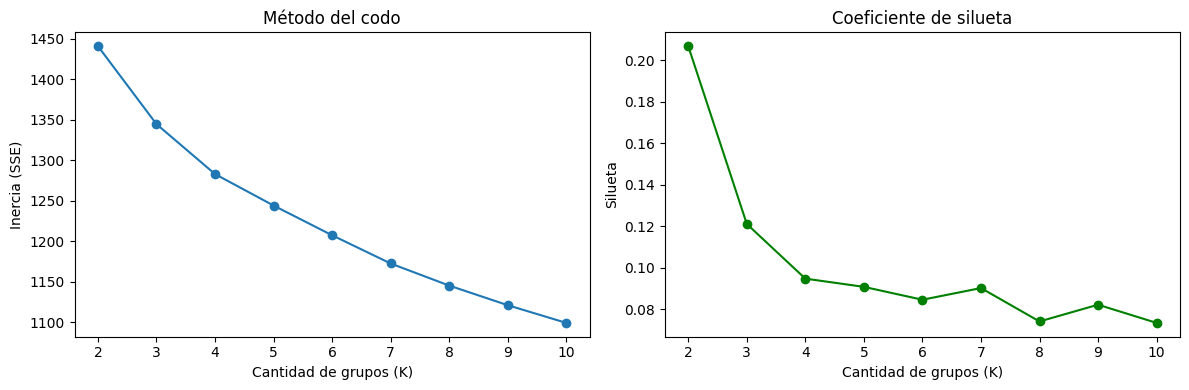

,Inercia,Silueta
K,,
2,1440.726,0.207
3,1344.574,0.121
4,1282.968,0.095
5,1244.193,0.091
6,1207.522,0.085
7,1172.713,0.090
8,1145.447,0.074
9,1121.285,0.082
10,1099.459,0.073


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Matriz de perfiles (una fila por cliente) y valores de K a probar
X_cli = perfiles.values
ks = range(2, 11)
inercias, siluetas = [], []

# k-means para cada K: se guarda la inercia (método del codo) y la silueta.
# n_init=10 repite el algoritmo con 10 inicios distintos y se queda con el mejor
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_cli)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cli, km.labels_))

# Gráficos del codo y de la silueta, uno al lado del otro
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(ks, inercias, marker="o")
ejes[0].set(title="Método del codo", xlabel="Cantidad de grupos (K)", ylabel="Inercia (SSE)")
ejes[1].plot(ks, siluetas, marker="o", color="green")
ejes[1].set(title="Coeficiente de silueta", xlabel="Cantidad de grupos (K)", ylabel="Silueta")
plt.tight_layout()
plt.show()

pd.DataFrame({"K": list(ks), "Inercia": inercias, "Silueta": siluetas}).round(3).set_index("K")

## S.3 · Interpretación de los segmentos (K = 4)

La silueta es baja para todos los valores de K (entre 0,07 y 0,21): los perfiles de compra de los clientes forman más un continuo que grupos bien separados. Siguiendo la clase C4 ("de los grupos a la comprensión"), evaluamos si los grupos son **interpretables y útiles** analizando sus **centroides**: cada valor indica en qué proporción de sus compras el cliente típico del segmento lleva ese producto.

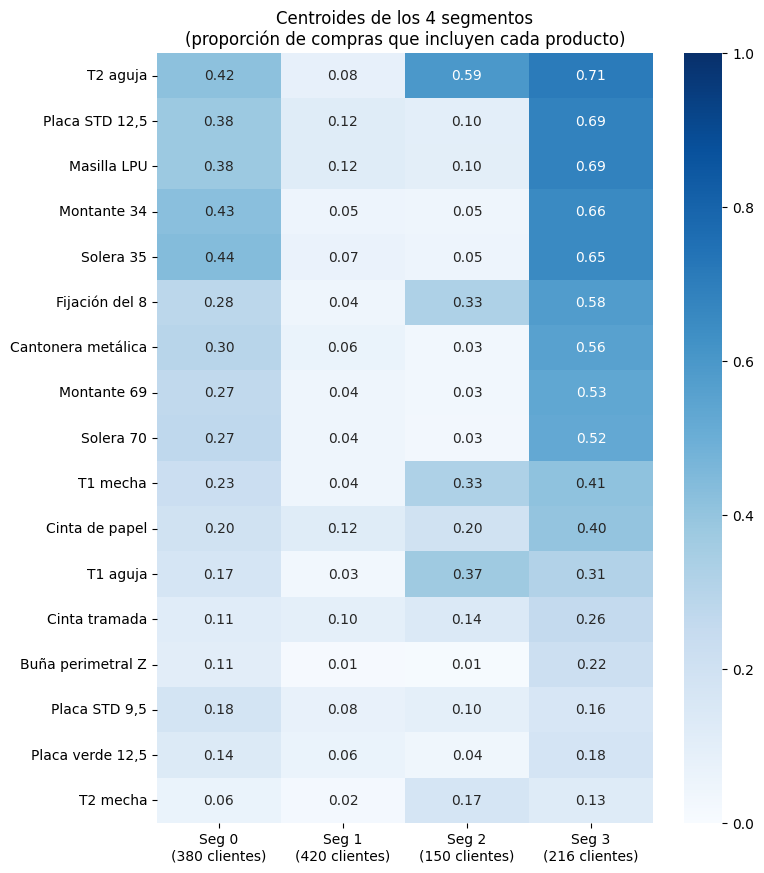

In [29]:
# k-means final con K = 4
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_cli)

# Segmento asignado a cada cliente y tamaño de cada segmento
segmento = pd.Series(km.labels_, index=perfiles.index, name="segmento")
tamanios = segmento.value_counts().sort_index()

# Centroides: el cliente "típico" de cada segmento (.T transpone: productos en filas)
centroides = pd.DataFrame(km.cluster_centers_, columns=perfiles.columns,
                          index=[f"Seg {i}\n({tamanios[i]} clientes)" for i in range(K)]).T

# Solo los productos que alcanzan 0,15 en algún segmento, ordenados por su valor máximo
relevantes = centroides[centroides.max(axis=1) >= 0.15]
relevantes = relevantes.loc[relevantes.max(axis=1).sort_values(ascending=False).index]

# Mapa de calor de los centroides para interpretar cada segmento
plt.figure(figsize=(8, 10))
sns.heatmap(relevantes, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title(f"Centroides de los {K} segmentos\n(proporción de compras que incluyen cada producto)")
plt.ylabel("")
plt.show()

## S.4 · Segmentos y combos propuestos

A partir de los centroides se identificaron cuatro perfiles:

| Segmento | Perfil |
|---|---|
| **Obra completa Durlock** | Llevan habitualmente todo el sistema: placa, perfiles, tornillería, masilla, cinta y cantonera |
| **Reposición de tornillería** | Compran tornillos y fijaciones, pero casi nunca placa ni perfiles (hipótesis: los compran a otro proveedor) |
| **Durlock parcial** | Mismo patrón que la obra completa, con la mitad de frecuencia |
| **Compradores diversos** | Perfil difuso, sin productos que se repitan |

Para cada segmento, los combos se derivan de los datos: se toma lo que **ya compra** (presente en ≥ 35% de sus compras) y se propone **lo que le falta** respecto del kit completo (productos que el segmento *Obra completa* lleva en ≥ 50% de sus compras).

In [30]:
# Nombres de los segmentos, según lo interpretado en el mapa de calor del paso S.3.
# k-means numera los grupos de forma arbitraria (el número puede cambiar al volver a correr
# con otros datos u otra versión de la librería), así que el nombre se asigna por el contenido
# del centroide y no por el número. Se usan las columnas de "tabla", que son las mismas del perfil.
c = pd.DataFrame(km.cluster_centers_, columns=tabla.columns)
placa, t2 = c["Placa STD 12,5"], c["T2 aguja"]

obra = placa.idxmax()                                   # el que más lleva placa: obra completa
tornilleria = (t2 - placa).drop(obra).idxmax()          # mucho tornillo y poca placa
resto = placa.drop([obra, tornilleria])
parcial, diversos = resto.idxmax(), resto.idxmin()      # de los otros dos, el que más lleva placa

NOMBRES = {obra: "Obra completa Durlock", tornilleria: "Reposición de tornillería",
           parcial: "Durlock parcial", diversos: "Compradores diversos"}
print("Número de k-means → segmento:", dict(sorted(NOMBRES.items())))
print()

# Centroides con el nombre de cada segmento. El kit de referencia es el de "Obra completa"
cent = pd.DataFrame(km.cluster_centers_, columns=tabla.columns,
                    index=[NOMBRES[i] for i in range(K)])
referencia = cent.loc["Obra completa Durlock"]

# Umbrales: "ya compra" = presente en ≥ 35% de sus compras; "kit" = ≥ 50% en Obra completa
YA_COMPRA, KIT = 0.35, 0.50

# Para cada segmento: lo que ya compra y lo que le falta respecto del kit completo
for seg in cent.index:
    fila = cent.loc[seg]
    ya_compra = fila[fila >= YA_COMPRA].sort_values(ascending=False).index.tolist()
    ofrecer = (referencia - fila)[(referencia >= KIT) & (fila < YA_COMPRA)].sort_values(ascending=False)

    print(f"■ {seg}  ({(segmento.map(NOMBRES) == seg).sum()} clientes)")
    print(f"   Ya compra:    {', '.join(ya_compra) if ya_compra else '—'}")
    print(f"   Para ofrecer: {', '.join(ofrecer.index) if len(ofrecer) else '— (ya lleva el kit completo)'}")
    print()

Número de k-means → segmento: {0: 'Durlock parcial', 1: 'Compradores diversos', 2: 'Reposición de tornillería', 3: 'Obra completa Durlock'}

■ Durlock parcial  (380 clientes)
   Ya compra:    Solera 35, Montante 34, T2 aguja, Placa STD 12,5, Masilla LPU
   Para ofrecer: Fijación del 8, Montante 69, Cantonera metálica, Solera 70

■ Compradores diversos  (420 clientes)
   Ya compra:    —
   Para ofrecer: T2 aguja, Montante 34, Solera 35, Placa STD 12,5, Masilla LPU, Fijación del 8, Cantonera metálica, Montante 69, Solera 70

■ Reposición de tornillería  (150 clientes)
   Ya compra:    T2 aguja, T1 aguja
   Para ofrecer: Montante 34, Solera 35, Placa STD 12,5, Masilla LPU, Cantonera metálica, Montante 69, Solera 70, Fijación del 8

■ Obra completa Durlock  (216 clientes)
   Ya compra:    T2 aguja, Placa STD 12,5, Masilla LPU, Montante 34, Solera 35, Fijación del 8, Cantonera metálica, Montante 69, Solera 70, T1 mecha, Cinta de papel
   Para ofrecer: — (ya lleva el kit completo)



---
# Objetivo 4 · Estimación de cantidades (exploratorio)

Estimamos **cuántos perfiles acompañan a una cantidad dada de placas** en una compra. Es un problema de **regresión** (clase C3-1): la salida es un número y no una clase. Se limita a placas y perfiles, que se venden por unidad; los accesorios quedan fuera porque un mismo producto base agrupa presentaciones con unidades muy distintas (por ejemplo, tornillos por 100 y por 10.000).

## Q.1 · Tabla de cantidades por compra

In [31]:
# Líneas de factura de los productos principales (placas y perfiles)
principales = sorted(productos.loc[productos["rol"] == "principal", "producto_base"].unique())
lineas_princ = datos_modelo[datos_modelo["producto_base"].isin(principales)]

# Control: en qué unidades se vende cada producto (deben ser comparables)
unidades_x_prod = lineas_princ.groupby("producto_base")["unidad_nombre"].unique()
print("Unidades en que se vende cada producto principal:")
print(unidades_x_prod)

# Igual que la tabla del paso 1.8, pero sumando cantidades en lugar de marcar 1/0.
# fillna(0): si la compra no llevó el producto, la cantidad es 0
cantidades = pd.crosstab(lineas_princ["compra_id"], lineas_princ["producto_base"],
                         values=lineas_princ["cantidad"], aggfunc="sum").fillna(0)
print()
print("Tabla de cantidades:", cantidades.shape)
# Media, mediana y máximo de cada producto (.T transpone: productos en filas)
cantidades.describe().T[["mean", "50%", "max"]].round(1).sort_values("mean", ascending=False).head(10)

Unidades en que se vende cada producto principal:
producto_base
Montante 34              [UNIDAD]
Montante 69              [UNIDAD]
Multiplaca 4 mm          [UNIDAD]
Multiplaca 6 mm          [UNIDAD]
OSB 11,1 mm              [UNIDAD]
OSB 9,5 mm               [UNIDAD]
Omega                    [UNIDAD]
PGC 100                  [UNIDAD]
PGC 70                   [UNIDAD]
PGU 100                  [UNIDAD]
PGU 70                   [UNIDAD]
Perfil larguero          [UNIDAD]
Perfil perimetral        [UNIDAD]
Placa Decoclasic 0,61    [UNIDAD]
Placa STD 12,5           [UNIDAD]
Placa STD 9,5            [UNIDAD]
Placa roja 12,5          [UNIDAD]
Placa verde 12,5         [UNIDAD]
Siding 6 mm              [UNIDAD]
Siding 8 mm              [UNIDAD]
Solera 35                [UNIDAD]
Solera 70                [UNIDAD]
Superboard 10 mm         [UNIDAD]
Superboard 8 mm          [UNIDAD]
Travesaño 0,61           [UNIDAD]
Travesaño 1,22           [UNIDAD]
Name: unidad_nombre, dtype: object

Tabla de cantida

,mean,50%,max
producto_base,,,
Montante 34,68.1,0.0,20000.0
"Placa STD 12,5",52.8,0.0,14388.0
Solera 35,41.2,0.0,11260.0
Montante 69,34.8,0.0,15232.0
"Travesaño 0,61",18.0,0.0,4800.0
Solera 70,17.2,0.0,7616.0
"Placa STD 9,5",12.6,0.0,2300.0
Multiplaca 6 mm,11.8,0.0,6930.0
"Placa verde 12,5",7.8,0.0,13800.0


## Q.2 · Entradas, salidas y división temporal

Entradas: cantidades de placas de yeso por compra. Salidas: cantidad de cada perfil (un modelo por perfil). Se usan las compras con al menos una placa de yeso, incluso las que no llevan perfiles, porque es la situación real del vendedor. La Placa Decoclasic queda fuera (cielorraso desmontable). Se usan los mismos meses de prueba que en el objetivo 1.

In [32]:
# Entradas: placas de yeso · salidas: los cuatro perfiles (un modelo por perfil)
placas = ["Placa STD 9,5", "Placa STD 12,5", "Placa roja 12,5", "Placa verde 12,5"]
perfiles = ["Montante 34", "Solera 35", "Montante 69", "Solera 70"]

# Solo las compras que llevan al menos una placa (suma por fila > 0)
con_placas = cantidades[cantidades[placas].sum(axis=1) > 0]
X_q = con_placas[placas]
Y_q = con_placas[perfiles]

# Mismos meses de prueba que el objetivo 1: compras cuyo id está en test
en_prueba = con_placas.index.isin(test.index)
X_q_train, X_q_test = X_q[~en_prueba], X_q[en_prueba]
Y_q_train, Y_q_test = Y_q[~en_prueba], Y_q[en_prueba]

print("Compras con placas:", len(con_placas))
print("Entrenamiento:", len(X_q_train), "| Prueba:", len(X_q_test))
print()
# Proporción de compras con placas que llevan cada perfil (cuántas veces la respuesta es 0)
print("Proporción de compras con placas que llevan cada perfil (entrenamiento):")
print((Y_q_train > 0).mean().round(2))

Compras con placas: 5557
Entrenamiento: 4726 | Prueba: 831

Proporción de compras con placas que llevan cada perfil (entrenamiento):
producto_base
Montante 34    0.48
Solera 35      0.48
Montante 69    0.36
Solera 70      0.36
dtype: float64


## Q.3 · Referencias: "siempre 0" y proporción histórica

Antes de entrenar modelos se miden dos referencias simples. "Siempre 0" predice que no se llevan perfiles. "Proporción histórica" calcula en entrenamiento cuántos perfiles se llevaron por cada placa y lo aplica a la prueba. Métricas: MAE (error promedio en unidades) y R² (proporción de la variación explicada).

In [33]:
# Métricas de regresión: MAE (error promedio en unidades) y R² (variación explicada)
from sklearn.metrics import mean_absolute_error, r2_score

# Total de placas de cada compra
total_placas_train = X_q_train.sum(axis=1)
total_placas_test = X_q_test.sum(axis=1)

resultados_q = []
for perfil in perfiles:
    real = Y_q_test[perfil]

    # Referencia 1: predecir siempre 0 perfiles
    pred_cero = pd.Series(0, index=real.index)
    resultados_q.append({"perfil": perfil, "metodo": "Siempre 0",
                         "MAE": mean_absolute_error(real, pred_cero),
                         "R2": r2_score(real, pred_cero)})

    # Referencia 2: proporción histórica = perfiles / placas en entrenamiento, aplicada a la prueba
    ratio = Y_q_train[perfil].sum() / total_placas_train.sum()
    pred_ratio = total_placas_test * ratio
    resultados_q.append({"perfil": perfil, "metodo": "Proporción histórica",
                         "MAE": mean_absolute_error(real, pred_ratio),
                         "R2": r2_score(real, pred_ratio),
                         "perfiles por placa": ratio})

# Promedio real por compra, para dar contexto al MAE
print("Promedio real por compra en prueba:")
print(Y_q_test.mean().round(1))
pd.DataFrame(resultados_q).round(2)

Promedio real por compra en prueba:
producto_base
Montante 34    75.4
Solera 35      42.2
Montante 69    53.5
Solera 70      24.9
dtype: float64


,perfil,metodo,MAE,R2,perfiles por placa
0,Montante 34,Siempre 0,75.41,-0.10,NaN
1,Montante 34,Proporción histórica,100.89,-0.07,0.73
2,Solera 35,Siempre 0,42.24,-0.13,NaN
3,Solera 35,Proporción histórica,57.97,-0.23,0.41
4,Montante 69,Siempre 0,53.54,-0.07,NaN
5,Montante 69,Proporción histórica,59.63,0.25,0.39
6,Solera 70,Siempre 0,24.88,-0.07,NaN
7,Solera 70,Proporción histórica,29.57,0.19,0.19


## Q.4 · Regresión lineal y Random Forest

Para cada perfil se entrena una regresión lineal (C3-1) y un Random Forest de regresión (C3-2), usando las cantidades de cada tipo de placa como entrada. Las predicciones negativas se llevan a 0, porque una cantidad no puede ser negativa. Se comparan con las referencias del paso Q.3.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Copia de los resultados de Q.3, para que volver a correr la celda no duplique filas
resultados_q4 = resultados_q.copy()
modelos_q = {}

for perfil in perfiles:
    real = Y_q_test[perfil]
    # Dos modelos por perfil: regresión lineal (C3-1) y Random Forest de regresión (C3-2).
    # min_samples_leaf=5: cada hoja necesita al menos 5 compras, para no memorizar compras gigantes
    candidatos = [("Regresión lineal", LinearRegression()),
                  ("Random Forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                          random_state=42, n_jobs=-1))]
    for nombre, modelo in candidatos:
        # Entrena, predice y lleva a 0 las predicciones negativas (una cantidad no puede ser negativa)
        modelo.fit(X_q_train, Y_q_train[perfil])
        pred = np.clip(modelo.predict(X_q_test), 0, None)
        resultados_q4.append({"perfil": perfil, "metodo": nombre,
                              "MAE": mean_absolute_error(real, pred),
                              "R2": r2_score(real, pred)})
        # Se guarda cada modelo para el ejemplo práctico
        modelos_q[(perfil, nombre)] = modelo

# Tablas de MAE y R²: una fila por perfil y una columna por método
tabla_q = pd.DataFrame(resultados_q4)
print("MAE (menor es mejor):")
print(tabla_q.pivot(index="perfil", columns="metodo", values="MAE").round(1))
print()
print("R² (mayor es mejor):")
tabla_q.pivot(index="perfil", columns="metodo", values="R2").round(2)

MAE (menor es mejor):
metodo       Proporción histórica  Random Forest  Regresión lineal  Siempre 0
perfil                                                                       
Montante 34                 100.9           86.5             105.8       75.4
Montante 69                  59.6           51.1              57.2       53.5
Solera 35                    58.0           50.5              62.6       42.2
Solera 70                    29.6           27.4              29.9       24.9

R² (mayor es mejor):


metodo,Proporción histórica,Random Forest,Regresión lineal,Siempre 0
perfil,,,,
Montante 34,-0.07,0.30,-0.01,-0.10
Montante 69,0.25,0.31,0.29,-0.07
Solera 35,-0.23,0.21,-0.52,-0.13
Solera 70,0.19,0.19,0.10,-0.07


## Q.5 · Modelo en dos etapas

Se separa el problema en dos preguntas. Etapa 1: un clasificador (Random Forest, como en el objetivo 1) estima la probabilidad de que la compra lleve el perfil. Etapa 2: una regresión (Random Forest) entrenada solo con las compras que llevan el perfil estima cuántos. Se prueban dos formas de combinarlas: "valor esperado" (probabilidad × cantidad) y "decisión" (la cantidad si la probabilidad es ≥ 0,5; 0 si no).

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

resultados_q5 = resultados_q4.copy()
f1_etapa1 = {}

# Modelo en dos etapas, para cada perfil
for perfil in perfiles:
    real = Y_q_test[perfil]
    # Clase para la etapa 1: ¿la compra lleva el perfil? (True / False)
    lleva_train = Y_q_train[perfil] > 0

    # Etapa 1: clasificador que estima la probabilidad de llevar el perfil.
    # Su F1 se compara con el del objetivo 1
    clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    clf.fit(X_q_train, lleva_train)
    prob = clf.predict_proba(X_q_test)[:, 1]
    f1_etapa1[perfil] = f1_score(real > 0, prob >= 0.5)

    # Etapa 2: regresión entrenada solo con las compras que SÍ llevan el perfil (¿cuántos?)
    reg = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    reg.fit(X_q_train[lleva_train], Y_q_train.loc[lleva_train, perfil])
    cant_si_lleva = reg.predict(X_q_test)

    # Dos formas de combinar las etapas:
    # valor esperado = probabilidad × cantidad · decisión = cantidad si prob. ≥ 0,5, si no 0
    pred_esperado = prob * cant_si_lleva
    pred_decision = np.where(prob >= 0.5, cant_si_lleva, 0)

    # Se agregan los dos resultados a la tabla
    for nombre, pred in [("2 etapas: valor esperado", pred_esperado),
                         ("2 etapas: decisión", pred_decision)]:
        resultados_q5.append({"perfil": perfil, "metodo": nombre,
                              "MAE": mean_absolute_error(real, pred),
                              "R2": r2_score(real, pred)})
    # Se guardan los modelos de las dos etapas
    modelos_q[(perfil, "clasificador")] = clf
    modelos_q[(perfil, "regresor si lleva")] = reg

# Resultados: F1 de la etapa 1 y tablas de MAE y R² con los seis métodos
print("F1 de la etapa 1 (¿lleva el perfil?):", {k: round(v, 2) for k, v in f1_etapa1.items()})
tabla_q = pd.DataFrame(resultados_q5)
print()
print("MAE (menor es mejor):")
print(tabla_q.pivot(index="perfil", columns="metodo", values="MAE").round(1))
print()
print("R² (mayor es mejor):")
tabla_q.pivot(index="perfil", columns="metodo", values="R2").round(2)

F1 de la etapa 1 (¿lleva el perfil?): {'Montante 34': 0.58, 'Solera 35': 0.57, 'Montante 69': 0.46, 'Solera 70': 0.45}

MAE (menor es mejor):
metodo       2 etapas: decisión  2 etapas: valor esperado  \
perfil                                                      
Montante 34                86.3                      85.6   
Montante 69                58.4                      52.1   
Solera 35                  53.1                      50.0   
Solera 70                  28.6                      27.4   

metodo       Proporción histórica  Random Forest  Regresión lineal  Siempre 0  
perfil                                                                         
Montante 34                 100.9           86.5             105.8       75.4  
Montante 69                  59.6           51.1              57.2       53.5  
Solera 35                    58.0           50.5              62.6       42.2  
Solera 70                    29.6           27.4              29.9       24.9  

R² (mayor 

metodo,2 etapas: decisión,2 etapas: valor esperado,Proporción histórica,Random Forest,Regresión lineal,Siempre 0
perfil,,,,,,
Montante 34,0.13,0.33,-0.07,0.30,-0.01,-0.10
Montante 69,-0.07,0.31,0.25,0.31,0.29,-0.07
Solera 35,-0.16,0.27,-0.23,0.21,-0.52,-0.13
Solera 70,-0.13,0.23,0.19,0.19,0.10,-0.07


## Q.6 · Ejemplo práctico

Se usa el Random Forest directo (el más simple, con resultados equivalentes al de dos etapas) para estimar los perfiles de algunas compras de ejemplo. Primero se miran las cantidades típicas de placas en las compras reales.

In [36]:
# Modelo adoptado: Random Forest directo (el más simple, con resultados equivalentes)
rf_q = {p: modelos_q[(p, "Random Forest")] for p in perfiles}

# Cantidades típicas: X > 0 deja vacías las compras sin esa placa y describe() las ignora
print("Cantidades típicas de cada placa (solo compras que la llevan, entrenamiento):")
print(X_q_train[X_q_train > 0].describe().T[["count", "25%", "50%", "75%"]])

# Compras de ejemplo: cada fila son las cantidades de STD 9,5, STD 12,5, roja y verde
ejemplos = pd.DataFrame(
    [[0,  20,  0,  0],
     [0, 100,  0,  0],
     [0, 300,  0,  0],
     [0,   0,  0, 50],
     [0, 100,  0, 30]],
    columns=placas,
    index=["20 STD 12,5", "100 STD 12,5", "300 STD 12,5", "50 verdes", "100 STD 12,5 + 30 verdes"])

# Predicción de cada perfil para cada ejemplo, sin negativos y redondeada a unidades
for p in perfiles:
    ejemplos[p] = np.clip(rf_q[p].predict(ejemplos[placas]), 0, None).round(0)

ejemplos[perfiles]


Cantidades típicas de cada placa (solo compras que la llevan, entrenamiento):
                   count  25%   50%   75%
producto_base                            
Placa STD 9,5     1560.0  5.0  20.0  80.0
Placa STD 12,5    3496.0  8.0  25.0  80.0
Placa roja 12,5    397.0  4.0   8.0  22.0
Placa verde 12,5  1169.0  5.0  12.0  34.0


,Montante 34,Solera 35,Montante 69,Solera 70
"20 STD 12,5",85.0,41.0,13.0,7.0
"100 STD 12,5",177.0,121.0,30.0,8.0
"300 STD 12,5",120.0,100.0,263.0,97.0
50 verdes,20.0,13.0,6.0,13.0
"100 STD 12,5 + 30 verdes",213.0,145.0,53.0,14.0


## Q.7 · Conclusiones del objetivo 4

**Qué se hizo.** Como objetivo exploratorio, se estimó la cantidad de cada perfil (Montante 34, Solera 35, Montante 69, Solera 70) a partir de las cantidades de placas de yeso de la compra. Se compararon dos referencias ("siempre 0" y proporción histórica), regresión lineal, Random Forest y un modelo en dos etapas (clasificador "¿lleva el perfil?" + regresión "¿cuántos?").

**Resultados.**
- Random Forest fue el mejor método simple: R² entre 0,19 y 0,31, y menor MAE que la proporción histórica y la regresión lineal en los cuatro perfiles.
- La regresión lineal fue la peor: las compras de gran volumen arrastran la recta.
- El modelo en dos etapas ("valor esperado") obtuvo resultados equivalentes. Como no se eligió con un conjunto de validación, se adopta el Random Forest directo por ser más simple.
- El MAE favorece predecir 0 cuando más de la mitad de las compras no lleva el perfil; por eso se analizaron MAE y R² juntos.

**Contraste con la regla técnica.** La proporción real del negocio (1,12 montantes y 0,60 soleras por placa) es coherente con la regla técnica para tabiques a doble cara (aprox. 1,3 a 1,6 montantes y 0,4 a 0,55 soleras por placa). El modelo la reproduce en compras medianas y grandes, pero sobreestima en compras chicas (con 20 placas estima casi 5 montantes por placa) y no siempre es monótono (más placas no garantiza más perfiles).

**Limitación principal.** El techo no está en el algoritmo sino en la información: la factura no indica si el cliente ya tiene perfiles ni qué tipo de tabique arma (la placa STD 12,5 se usa en tabiques de 35 y de 70). El clasificador de la etapa 1 solo alcanza F1 de 0,45 a 0,58.

**Uso propuesto.** Como referencia orientativa para el vendedor y, sobre todo, para planificar compras al proveedor en forma agregada, donde los errores individuales se compensan. No para fijar cantidades compra por compra.

**Mejoras futuras.** Sumar los accesorios de la compra como entrada (los tornillos T1 indican que se arma estructura), el segmento del cliente, y restricciones de monotonía (más placas → no menos perfiles).

---
# Etapa 4 · Puesta en producción

Según la clase C2-1, la puesta en producción (MLOps) contempla el **despliegue** del modelo, su **monitoreo continuo**, la **gestión de versiones** y la **documentación y auditoría**. Este trabajo no implementa la puesta en producción, pero la diseña para el ERP del mayorista (Andino Gestión, desarrollado en WinDev con base HFSQL).

## 4.1 · Demostración: sugerencia de accesorios para un pedido

La función `sugerir_accesorios` muestra cómo se usaría el modelo final en el día a día: recibe los productos que el cliente ya lleva y devuelve los accesorios confiables que probablemente le falten, con su probabilidad y prioridad (mismos umbrales que en la Etapa 3).

In [37]:
def sugerir_accesorios(productos_cargados, umbral=UMBRAL_MEDIA):
    # Control: los nombres tienen que coincidir con los productos base de la tabla de compras
    desconocidos = set(productos_cargados) - set(tabla.columns)
    assert not desconocidos, f"Productos desconocidos: {desconocidos}"

    # La compra nueva se arma en el mismo formato que la tabla del paso 1.8: 1 si lo lleva, 0 si no
    compra = pd.DataFrame(0, index=["pedido"], columns=tabla.columns)
    compra[list(productos_cargados)] = 1

    # Para cada accesorio confiable que todavía no lleva: probabilidad según su modelo final
    sugerencias = []
    for acc in confiables:
        if acc in productos_cargados:
            continue
        prob = modelos_finales[acc].predict_proba(compra.drop(columns=acc))[0, 1]
        if prob >= umbral:
            sugerencias.append({"Accesorio": acc, "Probabilidad": round(prob, 2),
                                "Prioridad": ("Alta" if prob >= UMBRAL_ALTA
                                              else "Media" if prob >= UMBRAL_MEDIA else "Baja")})

    # Resultado ordenado de mayor a menor probabilidad (tabla vacía si no hay nada para sugerir)
    if not sugerencias:
        return pd.DataFrame(columns=["Accesorio", "Probabilidad", "Prioridad"])
    return pd.DataFrame(sugerencias).sort_values("Probabilidad", ascending=False).reset_index(drop=True)


# Ejemplo 1: el cliente lleva placa y perfiles, sin tornillos ni terminación
print("Pedido 1: Placa STD 12,5 + Montante 34 + Solera 35")
display(sugerir_accesorios(["Placa STD 12,5", "Montante 34", "Solera 35"]))

# Ejemplo 2: ya lleva tornillos y masilla; ¿qué le falta?
print("Pedido 2: Placa STD 12,5 + Montante 34 + Solera 35 + T1 aguja + T2 aguja + Masilla LPU")
display(sugerir_accesorios(["Placa STD 12,5", "Montante 34", "Solera 35",
                            "T1 aguja", "T2 aguja", "Masilla LPU"]))

Pedido 1: Placa STD 12,5 + Montante 34 + Solera 35


,Accesorio,Probabilidad,Prioridad


Pedido 2: Placa STD 12,5 + Montante 34 + Solera 35 + T1 aguja + T2 aguja + Masilla LPU


,Accesorio,Probabilidad,Prioridad
0,Fijación del 8,0.85,Alta
1,Cantonera metálica,0.72,Media


In [38]:
# Pedido 1 sin umbral: ningún accesorio llega a 0,7. El modelo también usa lo que NO se lleva:
# compras con solo placa y perfiles suelen ser de clientes que compran la tornillería en otro lado
sugerir_accesorios(["Placa STD 12,5", "Montante 34", "Solera 35"], umbral=0)

,Accesorio,Probabilidad,Prioridad
0,Cantonera metálica,0.53,Baja
1,Masilla LPU,0.49,Baja
2,T1 aguja,0.39,Baja
3,T2 aguja,0.29,Baja
4,Fijación del 8,0.20,Baja
5,Base coat,0.17,Baja
6,T1 mecha,0.15,Baja
7,Cinta de papel,0.15,Baja
8,Cinta tramada,0.14,Baja
9,Malla sostén,0.00,Baja


## 4.2 · Diseño de la puesta en producción

**Despliegue.** Se propone un **proceso nocturno (batch)**: un script en Python lee lo facturado en el mes en curso desde la base del ERP, arma la compra cliente-mes de cada cliente, calcula los accesorios faltantes con los modelos finales y graba las sugerencias en una tabla de HFSQL. Cuando el vendedor carga el siguiente pedido de ese cliente (en mostrador o por teléfono/WhatsApp), el ERP muestra el aviso: *"este mes llevó placas y perfiles, pero todavía no llevó masilla (90%)"*. Este diseño no requiere cambiar la arquitectura del ERP y coincide con la unidad de análisis del modelo (la compra mensual). A fin de mes, el mismo proceso genera un **reporte comercial** con las posibles ventas perdidas por cliente (objetivo 2) y el combo sugerido para su segmento (objetivo 3). Como evolución, el modelo puede servirse con una **API** (por ejemplo, FastAPI) que el ERP consulte en el momento, para sugerir dentro del mismo pedido.

**Supervisión humana.** El modelo **sugiere**; la decisión de ofrecer el accesorio es del vendedor. Nada se agrega automáticamente al pedido.

**Monitoreo continuo.** Al cerrar cada mes se compara lo que el modelo esperaba con lo que el cliente realmente llevó, y se calcula el F1 de cada accesorio, igual que en la Etapa 2. También se registra qué sugerencias aceptó el cliente, que es la medida de impacto en el negocio. El control del paso 1.7 detecta artículos nuevos que todavía no tienen producto base asignado.

**Reentrenamiento.** Cada **trimestre**, con los datos acumulados, siguiendo el mismo esquema de validación temporal; o antes, si el F1 mensual de un accesorio cae por debajo de **0,5** (el umbral de "confiable"). Un accesorio que deja de ser confiable deja de generar sugerencias.

**Gestión de versiones.** Cada reentrenamiento se guarda como una versión nueva (por ejemplo, `v2026-12`), con el período de datos usado, los hiperparámetros por accesorio y las métricas en validación y prueba. Se conserva la versión anterior para volver atrás si la nueva funciona peor. La clasificación de productos (`productos.xlsx`) se versiona junto con el modelo.

**Documentación y auditoría.** Esta notebook documenta las decisiones y los resultados de la primera versión. En producción se registra cada sugerencia mostrada (fecha, cliente, accesorio, probabilidad, versión del modelo) y si fue aceptada, para poder auditar qué recomendó el sistema y por qué.

**Limitación a tener en cuenta.** El modelo se entrenó con compras **mensuales** completas, y en producción se aplica a un mes **en curso**, que puede estar incompleto. A principio de mes puede sugerir accesorios que el cliente pensaba comprar más adelante. Por eso las sugerencias se presentan como recordatorio y no como error del cliente.

**Lectura de la demostración y mejora propuesta.** En el pedido 2 (placa, perfiles, tornillos y masilla), el modelo sugiere fijación del 8 (0,85) y cantonera (0,72): el mismo "Kit terminación" que surge de la segmentación (objetivo 3) y las ventas perdidas más frecuentes (objetivo 2). En el pedido 1 (solo placa y perfiles), en cambio, ningún accesorio supera 0,7, y el tornillo T2 queda en 0,29, aunque técnicamente es imprescindible para colocar la placa. El modelo aprende **hábitos de compra**, no **necesidades técnicas**: en los datos, quien compra solo placa y perfiles suele tener los tornillos o comprarlos en otro lado. Como mejora se propone un **sistema híbrido**, que combine el modelo con **reglas del rubro** para los accesorios obligatorios (por ejemplo, "si lleva placa y no lleva T2, sugerir T2").

---
# Reflexión crítica

## R.1 · Conclusiones

El trabajo se propuso detectar qué artículos se venden juntos en un mayorista de construcción en seco, para identificar ventas perdidas y armar combos. Siguiendo la sugerencia del equipo docente, se priorizaron la predicción de productos acompañantes y la detección de ventas perdidas, y se sumaron la segmentación y la estimación de cantidades.

| Objetivo | Técnica | Resultado | Estado |
|---|---|---|---|
| 1. Productos acompañantes | Clasificación (árbol, regresión logística, k-NN, Random Forest) | Random Forest con ajuste por accesorio: F1 promedio 0,51; 11 de 20 accesorios confiables (F1 ≥ 0,5) | Logrado |
| 2. Ventas perdidas | Probabilidades del modelo final + umbral elegido midiendo el trade-off | 679 posibles ventas perdidas en jul–sep 2026 (284 de prioridad alta) | Logrado |
| 3. Segmentación y combos | k-means (K = 4) sobre el perfil de compra | 4 segmentos interpretables y 3 combos derivados de los datos | Logrado |
| 4. Estimación de cantidades | Regresión (lineal, Random Forest, dos etapas) | Random Forest, R² de 0,19 a 0,31; tendencia correcta en compras medianas y grandes | Parcial (exploratorio) |

**Hallazgos principales:**

- **El modelo aprende la lógica de una obra.** Sin que se le indique, el árbol de decisión descubre que la placa lleva a la masilla y que la masilla va con la cinta de papel: las reglas que surgen de los datos coinciden con el sistema constructivo.
- **La unidad de análisis importa.** Una factura tiene una mediana de 2 artículos y una compra mensual del cliente, de 4. Analizar factura por factura habría ocultado buena parte de los productos que se llevan juntos.
- **Tres métodos llegan a la misma conclusión.** El "Kit terminación" (fijación y cantonera) aparece como la venta perdida más frecuente (objetivo 2), como lo que le falta al segmento "Durlock parcial" (objetivo 3) y como la sugerencia de la demostración de la Etapa 4. Esa coincidencia entre técnicas distintas da confianza en el resultado.
- **Las ventas perdidas están repartidas.** Afectan al 34% de los clientes activos y los 10 primeros concentran solo el 7%. No se resuelven con una campaña a pocos clientes, sino con un proceso en el punto de venta (Etapa 4).
- **El modelo aprende hábitos, no necesidades técnicas.** Cuando un cliente compra la tornillería a otro proveedor, el modelo deja de sugerirla. Es una limitación, pero también es justamente la oportunidad comercial que el trabajo busca hacer visible.

## R.2 · Limitaciones

**De los datos**

- **Un solo mayorista.** Los patrones de compra corresponden a un único negocio y a su zona; no se puede asumir que se repitan en otros mayoristas sin volver a entrenar.
- **Las facturas muestran lo que se vendió, no lo que se necesitó.** No registran lo que el cliente compró a otros proveedores, lo que ya tenía en obra ni lo que pidió y no había en stock.
- **Reducción de los datos.** Se trabajó solo con construcción en seco y con los artículos presentes en al menos el 2% de las compras (el 15% de los artículos, que cubre el 84% de las líneas). Los productos poco frecuentes quedan fuera del análisis.
- **Clasificación manual de productos.** La asignación de cada código a un producto base y a un rol (principal, accesorio, herramienta) se hizo con conocimiento del rubro, pero no fue validada formalmente por el área comercial.
- **La compra mensual es una convención.** Agrupar por cliente y mes captura mejor lo que se lleva junto que la factura, pero una obra que se abastece a caballo entre dos meses queda partida en dos compras.

**De los modelos y la evaluación**

- **Las ventas perdidas son "posibles".** Que el modelo espere un accesorio y el cliente no lo lleve puede deberse a que lo compró en otro lado (venta perdida real), a que ya lo tenía o a que lo compró en otro mes. Los datos no permiten distinguir esos casos.
- **No todos los accesorios se pueden predecir.** 9 de los 20 accesorios no alcanzan un F1 de 0,5, sobre todo los menos frecuentes, por falta de ejemplos. Para dos de ellos (tapa de inspección y arandela EIFS), el ajuste por accesorio quedó por debajo de la configuración por defecto.
- **Un único período de prueba.** Los resultados se midieron en un trimestre (julio a septiembre de 2026). Otro período, con otra estacionalidad, podría dar valores algo distintos.
- **Segmentos poco separados.** La silueta es baja para todo K: los perfiles de compra forman más un continuo que grupos nítidos. Los segmentos son útiles para interpretar, pero sus límites son difusos; los nichos (steel framing, cielorraso, placas cementicias) no forman un grupo propio, y el segmento "Compradores diversos" no tiene un combo claro. La hipótesis de que el segmento "Reposición de tornillería" compra la placa y los perfiles a otro proveedor no pudo confirmarse.
- **Las cantidades dependen de información que la factura no tiene.** La estimación de perfiles explica entre el 19% y el 31% de la variación y no es monótona: la factura no indica qué tipo de tabique se arma ni si el cliente ya tiene perfiles.

**Del uso real**

- **El modelo aprende hábitos, no necesidades.** Si un cliente siempre compra la tornillería a otro proveedor, el modelo deja de sugerirla, aunque sea técnicamente imprescindible.
- **El mes en curso está incompleto.** El modelo se entrenó con meses completos; aplicado a principio de mes, puede sugerir accesorios que el cliente pensaba comprar más adelante.
- **No se midió el impacto comercial.** El trabajo identifica oportunidades, pero no demuestra cuántas se convierten en ventas: eso requiere ponerlo a prueba con los vendedores.
- **Validación del negocio informal.** El equipo viene del área de sistemas; el conocimiento del rubro se incorporó a partir del trabajo con el cliente y su ERP, pero no participaron formalmente vendedores ni personas del área de obra.

## R.3 · Posibles mejoras

**Sobre el modelo**

- **Sistema híbrido.** Combinar el modelo con reglas del rubro para los accesorios técnicamente obligatorios (por ejemplo, "si lleva placa y no lleva tornillo T2, sugerirlo"). El modelo aporta los hábitos de compra y las reglas cubren las necesidades técnicas *(responde a: el modelo aprende hábitos, no necesidades)*.
- **Más variables de entrada.** Sumar el segmento del cliente y su historial (por ejemplo, qué accesorios llevó en los meses anteriores) para la predicción de acompañantes; y los accesorios de la compra para la estimación de cantidades, ya que los tornillos de estructura indican que se arma un tabique *(responde a: las cantidades dependen de información que la factura no tiene)*.
- **Más períodos de evaluación.** Repetir la evaluación sobre varios trimestres (validación temporal en ventana móvil) para medir la estabilidad de los resultados frente a la estacionalidad *(responde a: un único período de prueba)*.
- **Otros algoritmos del curso.** Probar métodos de boosting como LightGBM (clase C3-2), que suelen rendir bien con clases desbalanceadas, para los accesorios que hoy no alcanzan el umbral *(responde a: no todos los accesorios se pueden predecir)*.

**Sobre los datos**

- **Registrar los pedidos no satisfechos.** Incorporar los pedidos que no se pudieron cumplir por falta de stock permitiría separar las ventas perdidas por faltante de las que el cliente compró en otro lado *(responde a: las ventas perdidas son "posibles")*.
- **Validar la clasificación de productos con el área comercial**, e incorporar más mayoristas para comprobar si los patrones se repiten *(responde a: clasificación manual y un solo mayorista)*.

**Sobre el uso real**

- **Prueba comercial.** Mostrar las sugerencias a los vendedores durante algunos meses y registrar cuáles acepta el cliente. Es la forma de medir el impacto real del modelo y, de paso, de confirmar o descartar las hipótesis: por ejemplo, ofrecer el "Kit estructura" al segmento "Reposición de tornillería" para ver si compra placa y perfiles *(responde a: no se midió el impacto comercial; hipótesis sin confirmar)*.
- **Ajustar la sugerencia al momento del mes.** Usar umbrales más altos al principio del mes, cuando la compra todavía está incompleta, o comparar contra lo que el cliente suele llevar a esa altura del mes *(responde a: el mes en curso está incompleto)*.
- **Servir el modelo con una API**, para sugerir dentro del mismo pedido mientras se carga, como evolución del proceso nocturno propuesto en la Etapa 4.
- **Sumar al equipo a vendedores y personal de obra** en la validación de los resultados y en el diseño de las sugerencias *(responde a: validación del negocio informal)*.

## R.4 · Implicancias éticas

Analizamos el trabajo con las siete dimensiones de la ética en IA que, según Jobin y Vayena (2019), comparten los marcos éticos globales (clase C8), más la sostenibilidad. Se trata de un sistema de recomendación comercial y no de un sistema que decide sobre personas, por lo que sus riesgos son menores que en los casos de alto impacto vistos en clase (justicia, salud, finanzas); aun así, cada dimensión tiene implicancias concretas.

**1. Consideración del sesgo.** Los datos reflejan a los clientes que más compran: la segmentación incluye solo a los clientes con al menos 3 compras mensuales (el 29% de los clientes, que hace el 73% de las compras), y los modelos aprenden sobre todo de ellos. Los clientes nuevos u ocasionales y los productos poco frecuentes quedan subrepresentados. Además, un recomendador tiende a reforzar lo que ya se vende: si las sugerencias influyen en las compras, los datos futuros reflejarán esas mismas sugerencias. Por eso proponemos medir el desempeño por segmento en el monitoreo. El modelo no usa atributos personales: trabaja solo con productos comprados.

**2. Transparencia y explicabilidad.** El árbol de decisión del paso 2.4 permite leer las reglas que aprendió el modelo ("si lleva placa, probablemente lleve masilla"), y la importancia de los atributos muestra qué productos pesan en cada predicción. El Random Forest final es menos interpretable que un árbol individual, pero cada sugerencia se presenta con su probabilidad y su prioridad, y la notebook documenta todas las decisiones metodológicas y sus resultados.

**3. Privacidad y protección de datos.** Los datos no contienen nombres, CUIT ni precios: cada cliente se identifica solo por un código interno. Para la entrega, clientes y facturas se renumeraron al azar, sin conservar la tabla de equivalencias, y se incluyó únicamente la línea de negocio analizada (construcción en seco), siguiendo el principio de minimización: compartir solo lo necesario. Esto protege tanto a los clientes como la información comercial del mayorista.

**4. Supervisión y control humano.** El sistema sugiere y el vendedor decide: nada se agrega automáticamente al pedido. Para evitar la confianza ciega en el sistema (*automation bias*), las sugerencias se presentan como recordatorio, con su probabilidad, y una posible venta perdida no se trata como un error del cliente ni del vendedor.

**5. Responsabilidad y rendición de cuentas.** La decisión de ofrecer un producto y el uso de los reportes son responsabilidad del mayorista y de su equipo comercial. Para que esa responsabilidad sea ejercible, la Etapa 4 propone registrar cada sugerencia mostrada (fecha, cliente, accesorio, probabilidad, versión del modelo) y si fue aceptada, y versionar los modelos: sin trazabilidad no hay responsabilidad.

**6. Monitoreo y evaluación continua.** Los hábitos de compra cambian con los productos, los precios y la temporada. La Etapa 4 propone medir el F1 de cada accesorio todos los meses, reentrenar cada trimestre o antes si un accesorio cae por debajo del umbral, y detectar artículos nuevos sin clasificar. Un accesorio que deja de ser confiable deja de generar sugerencias.

**7. Colaboración y enfoque multidisciplinario.** El equipo viene del área de sistemas, y el conocimiento del rubro se incorporó a partir del trabajo con el cliente y su ERP: la clasificación de los productos, la interpretación de los segmentos y la validación de los resultados (por ejemplo, el contraste con la regla técnica de montantes y soleras). Es una colaboración parcial: un uso real requiere sumar a vendedores y personal de obra, que conocen mejor que nadie lo que el cliente necesita.

**8. Sostenibilidad.** Los modelos son chicos (árboles y Random Forest sobre una tabla de unos 12.000 registros), se entrenan en minutos en una computadora personal, sin GPU, y el proceso propuesto corre una vez por noche con reentrenamiento trimestral. El costo energético es mínimo comparado con modelos de mayor escala, y proporcionado al problema.

## R.5 · Aprendizajes

- **El conocimiento del negocio pesa tanto como el algoritmo, y el nuestro tiene límites.** Como desarrolladores del sistema de gestión conocemos el negocio, pero no en profundidad. Las decisiones que más cambiaron los resultados (agrupar los códigos en productos base, definir qué es principal y qué es accesorio, elegir la compra mensual como unidad de análisis) fueron de negocio, no de algoritmo. Con la participación directa del cliente y de sus vendedores en esas decisiones y en la validación de los resultados, el trabajo habría salido mejor. Es lo primero que cambiaríamos al repetirlo.
- **Más datos rinden más que más ajuste.** Pasar de 3 a 24 meses de historia mejoró los resultados, sobre todo en los accesorios menos frecuentes, más que la búsqueda de hiperparámetros.
- **Las métricas pueden engañar si no se eligen según el problema.** Con clases desbalanceadas, un modelo que siempre responde "no lleva" tiene un accuracy alto y no sirve para nada; en la estimación de cantidades, el MAE premiaba predecir siempre 0. Aprendimos a elegir la métrica según la pregunta y a mirar más de una.
- **Cuando técnicas distintas coinciden, el resultado gana confianza.** El "Kit terminación" apareció en la clasificación (ventas perdidas), en el clustering (segmentos) y en la demostración de la Etapa 4. Ninguna técnica sola lo habría respaldado tanto.
- **Pasar de la notebook al uso real obliga a pensar en otras cosas.** Diseñar la puesta en producción en un sistema real planteó problemas que en la notebook no aparecen: el mes en curso incompleto, el rol del vendedor, el monitoreo y el reentrenamiento.
- **Pensar en SQL ayuda a aprender pandas.** Viniendo de sistemas, relacionar cada operación con su equivalente en SQL (un *merge* con un JOIN, un *crosstab* con un PIVOT, un *np.where* con un CASE WHEN) hizo mucho más fácil entender y escribir el código.